# Phân tích cảm xúc review phim IMDB bằng LSTM

Bài này dùng LSTM để phân loại review phim IMDB thành positive hoặc negative, rồi so với mạng neural cơ bản và vài phương pháp học máy quen thuộc. Câu hỏi đặt ra là: một mô hình đọc được thứ tự từ như LSTM có thật sự tốt hơn các mô hình chỉ đếm từ không, và có đáng với chi phí bỏ ra không.

Các mô hình được đem ra so sánh:

| Nhóm | Mô hình | Mã |
|---|---|---|
| Học máy trên TF-IDF | Logistic Regression, Linear SVM, Multinomial Naive Bayes | `lr`, `svm`, `nb` |
| Mạng neural cơ bản | Embedding + GlobalAveragePooling + Dense | `nn_avg` |
| | MLP trên TF-IDF | `mlp_tfidf` |
| Mạng hồi quy | LSTM | `lstm` |
| | GRU, BiLSTM | `gru`, `bilstm` |
| | LSTM + GloVe (cho học tiếp / đóng băng) | `lstm_glove`, `lstm_glove_frozen` |

## Tóm tắt kết quả

Logistic Regression trên TF-IDF cho kết quả tốt nhất với 90,3% accuracy trên test, SVM và MLP trên TF-IDF theo sát quanh 90%. LSTM chỉ đạt 86,8%, thấp hơn cả `nn_avg` là mô hình chỉ lấy trung bình embedding (87,9%), còn GRU, BiLSTM và LSTM dùng GloVe đều nằm trong khoảng 85–86,5%.

Khi xáo trộn thứ tự từ trong review, LSTM chỉ giảm 0,5 điểm, tức là với 20.000 review nó gần như chưa tận dụng được thứ tự từ. Trong khi đó LSTM tốn thời gian train gấp khoảng 10 lần và nhiều tham số gấp 26 lần Logistic Regression. Vì vậy với bài toán này, TF-IDF kết hợp một mô hình tuyến tính vẫn là lựa chọn hợp lý hơn.

## 1. Setup

Import thư viện và đặt các hằng số dùng chung ở một chỗ cho dễ sửa. Notebook chạy trên Kaggle, nhớ bật GPU T4 và Internet trong Settings trước khi chạy.

In [1]:
import os
import re
import time
import glob
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import datasets
import tensorflow as tf
import keras
from keras import layers
from datasets import load_dataset
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

In [2]:
for lib in [tf, keras, sklearn, scipy, datasets, pd, np, matplotlib, sns]:
    print(lib.__name__, lib.__version__)

tensorflow 2.20.0
keras 3.13.2
sklearn 1.6.1
scipy 1.16.3
datasets 4.8.5
pandas 2.3.3
numpy 2.1.3
matplotlib 3.10.0
seaborn 0.13.2


In [3]:
SEED = 42
SEEDS = [42, 43, 44]
VOCAB_SIZE = 20000
EMBED_DIM = 128
GLOVE_DIM = 100
MLP_FEATURES = 20000
BATCH_SIZE = 64
EPOCHS = 15
RESULTS_DIR = "results"
FIG_DIR = "results/figures"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

os.makedirs(FIG_DIR, exist_ok=True)
keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", palette=PALETTE)

In [4]:
gpus = tf.config.list_physical_devices("GPU")
print(gpus)
DEVICE = "gpu" if gpus else "cpu"

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Dữ liệu

Dữ liệu là bộ IMDB của Stanford, tải qua HuggingFace. Bộ này chia sẵn 25.000 review để train và 25.000 review để test, nhãn 0 là negative, 1 là positive. Không dùng `keras.datasets.imdb` vì bản đó đã bị mã hóa thành số, không làm TF-IDF được.

In [5]:
imdb = load_dataset("stanfordnlp/imdb")
print(imdb)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [6]:
full_train_df = imdb["train"].to_pandas()
test_df = imdb["test"].to_pandas()
print(full_train_df.shape, test_df.shape)
full_train_df.head()

(25000, 2) (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


Có một điểm cần để ý: tập train của HuggingFace đang xếp theo nhãn, hết negative rồi mới tới positive.

In [7]:
print("5 nhãn đầu:", full_train_df["label"].to_numpy()[:5])
print("5 nhãn cuối:", full_train_df["label"].to_numpy()[-5:])

5 nhãn đầu: [0 0 0 0 0]
5 nhãn cuối: [1 1 1 1 1]


Lấy ra 20% tập train làm validation để tune và early stopping, chia stratified để giữ tỉ lệ nhãn. Tập test để nguyên và chỉ dùng ở phần 8. Mọi mô hình đều train trên cùng 20.000 review này cho công bằng.

In [8]:
train_df, val_df = train_test_split(full_train_df, test_size=0.2, stratify=full_train_df["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))
print("20 nhãn đầu của train:", y_train[:20])

train: 20000 | val: 5000 | test: 25000
20 nhãn đầu của train: [1 0 1 1 1 1 0 1 1 1 0 1 1 1 0 1 0 0 0 0]


## 3. Khám phá dữ liệu

Trước khi làm sạch và chọn độ dài chuỗi, xem qua dữ liệu một chút: nhãn có cân bằng không, review dài cỡ nào, trông ra sao. Các thống kê về độ dài chỉ tính trên train.

In [9]:
label_counts = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
})
label_counts

,train,val,test
label,,,
0,10000,2500,12500
1,10000,2500,12500


In [10]:
train_df["n_words"] = train_df["text"].str.split().str.len()
print(train_df["n_words"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).round(1))

count    20000.0
mean       233.1
std        173.3
min         10.0
25%        127.0
50%        174.0
75%        283.0
90%        457.0
95%        593.0
max       2470.0
Name: n_words, dtype: float64


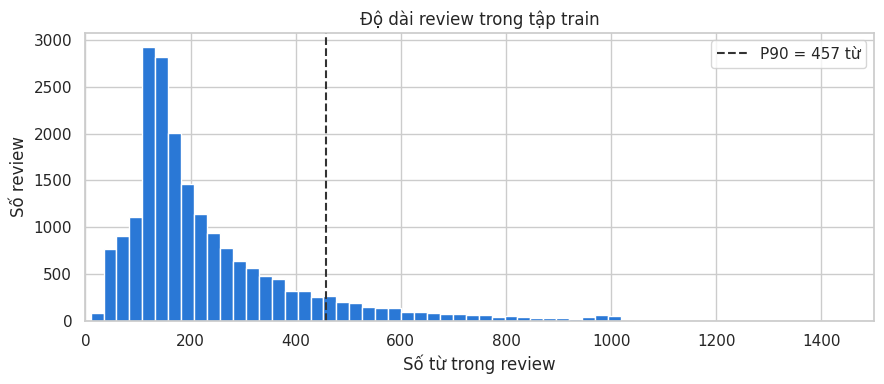

In [11]:
p90_words = train_df["n_words"].quantile(0.9)

plt.figure(figsize=(9, 4))
plt.hist(train_df["n_words"], bins=100)
plt.axvline(p90_words, color="#333333", linestyle="--", linewidth=1.5, label=f"P90 = {p90_words:.0f} từ")
plt.xlim(0, 1500)
plt.xlabel("Số từ trong review")
plt.ylabel("Số review")
plt.title("Độ dài review trong tập train")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eda_length_hist.png", dpi=150)
plt.show()

In [12]:
train_df.groupby("label")["n_words"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,10000.0,230.6,166.5,10.0,128.0,175.0,277.2,1522.0
1,10000.0,235.7,179.8,12.0,125.0,174.0,289.0,2470.0


Xem thử vài review của mỗi lớp:

In [13]:
for label in [0, 1]:
    print("Nhãn", label)
    samples = train_df[train_df["label"] == label].sample(2, random_state=SEED)
    for text in samples["text"]:
        print(text[:600])
        print()

Nhãn 0
Really, really bad slasher movie. A psychotic person escapes from an asylum. Three years later he kills a sociology professor, end of scene. One semester yesterday later (hey, that's what the title card said) a new sociology professor is at the school. She makes friends with another female sociology professor who works there, and starts dating another professor. The students are all bored, as are we.<br /><br />There are a number of title cards indicating how much time has passed. Scenes are pretty short, and cut to different characters somewhere else, making for little progression of any kind

After Life is a Miracle, I did not expect much. It's hard to believe that these films were made by the same man as Do You Remember Dolly Bell, for instance. Zavet is two hours of silly antics with no story. The wild and unbridled humor of Underground seems to have degenerated into pathetic buffoonery here. It appears that Kusturica has been going steadily downhill since he started making 

In [14]:
has_br = train_df["text"].str.contains("<br />", regex=False)
print(f"Tỉ lệ review có thẻ <br />: {has_br.mean():.1%}")

Tỉ lệ review có thẻ <br />: 58.4%


Thử tìm những từ hay xuất hiện ở review positive hơn negative và ngược lại. Cách làm đơn giản là so tần suất của từ ở hai lớp bằng log tỉ lệ, chỉ xét những từ có mặt trong ít nhất 50 review.

In [15]:
count_vec = CountVectorizer(min_df=50)
counts = count_vec.fit_transform(train_df["text"])
words = count_vec.get_feature_names_out()

pos_counts = np.asarray(counts[y_train == 1].sum(axis=0)).ravel() + 1
neg_counts = np.asarray(counts[y_train == 0].sum(axis=0)).ravel() + 1
log_ratio = np.log(pos_counts / pos_counts.sum()) - np.log(neg_counts / neg_counts.sum())
order = np.argsort(log_ratio)

print("Đặc trưng positive:", ", ".join(words[order[::-1][:20]]))
print("Đặc trưng negative:", ", ".join(words[order[:20]]))

Đặc trưng positive: victoria, matthau, flawless, powell, perfection, superbly, wonderfully, voight, macy, masterful, technicolor, timeless, affection, delightful, gripping, captures, lemmon, andrews, beautifully, sullivan
Đặc trưng negative: stinker, dreck, unwatchable, mst3k, inane, incoherent, unfunny, waste, pointless, lousy, tripe, blah, laughable, poorly, horrid, wasting, atrocious, worst, awful, redeeming


In [16]:
train_texts = set(full_train_df["text"])
test_texts = set(test_df["text"])
print("Review trùng nhau trong train gốc:", full_train_df["text"].duplicated().sum())
print("Review trùng nhau trong test:", test_df["text"].duplicated().sum())
print("Review xuất hiện ở cả train gốc và test:", len(train_texts & test_texts))

Review trùng nhau trong train gốc: 96
Review trùng nhau trong test: 199
Review xuất hiện ở cả train gốc và test: 123


**Nhận xét.** Hai nhãn cân bằng tuyệt đối ở cả ba tập nên dùng accuracy để so sánh là hợp lý. Độ dài review chênh nhau khá nhiều: một nửa số review dưới 174 từ nhưng P90 đã là 457 và dài nhất tới 2.470 từ, còn positive và negative thì dài gần như nhau. Có 58,4% review chứa thẻ `<br />` nên bước làm sạch phải bỏ thẻ HTML. Phía positive lại có khá nhiều tên diễn viên như matthau, lemmon hay powell; vì train và test là các bộ phim khác nhau nên đây là kiểu tín hiệu dễ làm mô hình học thuộc. Số review trùng lặp rất ít so với 25.000 nên có thể bỏ qua.

## 4. Tiền xử lý

### 4.1 Làm sạch văn bản

Hàm làm sạch dùng chung cho mọi mô hình: chuyển về chữ thường, bỏ thẻ HTML như `<br />`, tách phủ định ("don't" thành "do not"), rồi bỏ các ký tự không phải chữ hay số. "won't" và "can't" phải thay trước, không thì sẽ ra "wo not" và "ca not".

Không bỏ stopwords, vì danh sách stopwords tiếng Anh có cả "not", "no", "never". Bỏ đi thì "not good" chỉ còn "good", mất luôn nghĩa của câu.

In [17]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.replace("won't", "will not")
    text = text.replace("can't", "can not")
    text = text.replace("n't", " not")
    text = re.sub(r"[^a-z0-9']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [18]:
example = train_df.loc[has_br & train_df["text"].str.contains("n't", regex=False), "text"].iloc[0]
print(example[:500])
print()
print(clean_text(example)[:500])

I am a Christian and I say this movie had terrible acting, unreal situations and a completely facade front for Christianity. You might as well watch "Remember the Titans" and at least not mix Christ in a football film like a formulaic steroid for losers. Let me make some really pressing comments of what bothered me in this film.<br /><br />1. The school was in Georgia and was a white academy school. I did not notice a single black student or player in the school. I deal with the White "Christian

i am a christian and i say this movie had terrible acting unreal situations and a completely facade front for christianity you might as well watch remember the titans and at least not mix christ in a football film like a formulaic steroid for losers let me make some really pressing comments of what bothered me in this film 1 the school was in georgia and was a white academy school i did not notice a single black student or player in the school i deal with the white christian academies in the s

In [19]:
train_df["clean"] = train_df["text"].apply(clean_text)
val_df["clean"] = val_df["text"].apply(clean_text)
test_df["clean"] = test_df["text"].apply(clean_text)

### 4.2 Chọn MAX_LEN

Mạng neural cần các chuỗi dài bằng nhau nên phải chọn một độ dài cố định. Ở đây lấy theo P90 số token của train rồi làm tròn lên bội số của 50, tức là khoảng 90% review được giữ nguyên, số còn lại bị cắt bớt phần cuối.

In [20]:
train_df["n_tokens"] = train_df["clean"].str.split().str.len()
test_df["n_tokens"] = test_df["clean"].str.split().str.len()

p90_tokens = train_df["n_tokens"].quantile(0.9)
print("P90 số token của train:", p90_tokens)

P90 số token của train: 459.0


In [21]:
MAX_LEN = int(np.ceil(p90_tokens / 50) * 50)
print("MAX_LEN =", MAX_LEN)
print(f"Tỉ lệ review train bị cắt: {(train_df['n_tokens'] > MAX_LEN).mean():.1%}")

MAX_LEN = 500
Tỉ lệ review train bị cắt: 8.0%


### 4.3 TF-IDF cho các mô hình học máy

Dùng cả unigram lẫn bigram để mô hình tuyến tính bắt được những cụm như "not good". Vectorizer chỉ fit trên train, còn val và test chỉ transform.

In [22]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, max_features=100000, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(train_df["clean"])
X_val_tfidf = tfidf.transform(val_df["clean"])
X_test_tfidf = tfidf.transform(test_df["clean"])
print(X_train_tfidf.shape, X_val_tfidf.shape, X_test_tfidf.shape)

(20000, 100000) (5000, 100000) (25000, 100000)


In [23]:
for phrase in ["not", "not good", "not bad", "never"]:
    print(phrase, phrase in tfidf.vocabulary_)

not True
not good True
not bad True
never True


### 4.4 Chuỗi token cho mạng neural

`TextVectorization` giữ 20.000 từ phổ biến nhất trong train, index 0 là phần đệm và index 1 là từ lạ (`[UNK]`). Văn bản được chuyển thành mảng số một lần rồi dùng chung cho mọi mạng neural. Review ngắn được đệm thêm ở cuối, review dài bị cắt ở cuối, và tầng Embedding đặt `mask_zero=True` để mô hình bỏ qua phần đệm.

In [24]:
vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, standardize=None, output_sequence_length=MAX_LEN)
vectorizer.adapt(train_df["clean"].to_numpy())
vocab = vectorizer.get_vocabulary()
print(len(vocab), vocab[:12])

I0000 00:00:1793031888.205059      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793031888.209576      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


20000 ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this')]


In [25]:
X_train_seq = np.array(vectorizer(train_df["clean"].to_numpy()))
X_val_seq = np.array(vectorizer(val_df["clean"].to_numpy()))
X_test_seq = np.array(vectorizer(test_df["clean"].to_numpy()))
print(X_train_seq.shape, X_val_seq.shape, X_test_seq.shape)

(20000, 500) (5000, 500) (25000, 500)


Kiểm tra lại một chút: dịch ngược một chuỗi token xem có khớp với văn bản không, và xem tỉ lệ từ lạ trên val là bao nhiêu.

In [26]:
decoded = " ".join(vocab[i] for i in X_train_seq[0] if i != 0)
print(train_df["clean"][0][:300])
print()
print(decoded[:300])

i have always been a huge james bond fanatic i have seen almost all of the films except for die another day and the world is not enough the graphic's for everything or nothing are breathtaking the voice talents wow i love pierce brosnan he is finally bond in a video game he is bond i enjoyed the pas

i have always been a huge james bond fanatic i have seen almost all of the films except for die another day and the world is not enough the [UNK] for everything or nothing are breathtaking the voice talents wow i love pierce brosnan he is finally bond in a video game he is bond i enjoyed the past bo


In [27]:
unk_rate = (X_val_seq == 1).sum() / (X_val_seq > 0).sum()
print(f"Tỉ lệ [UNK] trên val: {unk_rate:.2%}")

Tỉ lệ [UNK] trên val: 3.09%


**Nhận xét.** Hàm làm sạch chạy đúng như mong muốn: văn bản về chữ thường, mất thẻ `<br />` và dấu câu nhưng nội dung còn nguyên. P90 số token là 459 nên `MAX_LEN` được làm tròn lên 500, và chỉ 8,0% review train bị cắt. TF-IDF vẫn giữ được các bigram "not good", "not bad" nhờ không bỏ từ phủ định. Chuỗi token dịch ngược khớp với văn bản, chỉ vài từ hiếm như "graphic's" thành `[UNK]`, và tỉ lệ `[UNK]` trên val chỉ 3,09% nên vocab 20.000 từ là đủ dùng.

## 5. Học máy: Logistic Regression, Linear SVM, Naive Bayes

Ba mô hình này dùng chung ma trận TF-IDF ở 4.3. Với mỗi mô hình, thử vài giá trị siêu tham số, chọn giá trị cho accuracy tốt nhất trên val rồi train lại một lần nữa để đo thời gian.

Hàm `evaluate` bên dưới dùng cho mọi mô hình trong bài. Nó nhận điểm số của mô hình (xác suất, hoặc `decision_function` với SVM) và một ngưỡng để quyết định nhãn.

In [28]:
def evaluate(y_true, scores, threshold):
    y_pred = (scores > threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, scores),
    }


ml_models = {}

### 5.1 Logistic Regression

In [29]:
best_acc = 0
for C in [0.1, 0.3, 1, 3, 10]:
    model = LogisticRegression(C=C, solver="liblinear", max_iter=1000, random_state=SEED)
    model.fit(X_train_tfidf, y_train)
    val_acc = accuracy_score(y_val, model.predict(X_val_tfidf))
    print(f"C={C}: val_acc={val_acc:.4f}")
    if val_acc > best_acc:
        best_acc = val_acc
        best_lr_C = C

print("C tốt nhất:", best_lr_C)

C=0.1: val_acc=0.8612
C=0.3: val_acc=0.8826
C=1: val_acc=0.8994
C=3: val_acc=0.9064
C=10: val_acc=0.9100
C tốt nhất: 10


In [30]:
start = time.time()
lr_model = LogisticRegression(C=best_lr_C, solver="liblinear", max_iter=1000, random_state=SEED)
lr_model.fit(X_train_tfidf, y_train)
lr_time = time.time() - start

ml_models["lr"] = {
    "model": lr_model,
    "train_time": lr_time,
    "params": f"C={best_lr_C}",
    "n_params": X_train_tfidf.shape[1] + 1,
}
print(f"Thời gian train: {lr_time:.1f}s")

Thời gian train: 2.7s


Xem trọng số của Logistic Regression để biết n-gram nào đẩy dự đoán về positive hay negative, nhất là các cặp có và không có "not":

In [31]:
feature_names = tfidf.get_feature_names_out()
coef = lr_model.coef_[0]
order = np.argsort(coef)
print("Mạnh nhất cho positive:", ", ".join(feature_names[order[::-1][:20]]))
print("Mạnh nhất cho negative:", ", ".join(feature_names[order[:20]]))
print()
for phrase in ["good", "not good", "bad", "not bad", "worth", "not worth", "recommend", "not recommend"]:
    if phrase in tfidf.vocabulary_:
        print(f"{phrase}: {coef[tfidf.vocabulary_[phrase]]:.3f}")

Mạnh nhất cho positive: great, excellent, perfect, wonderful, today, the best, best, amazing, brilliant, loved, fun, love, superb, enjoyable, favorite, well, wonderfully, beautiful, bit, still
Mạnh nhất cho negative: bad, worst, awful, boring, the worst, poor, worse, waste, terrible, poorly, dull, horrible, nothing, no, unfortunately, disappointing, disappointment, annoying, not even, lame

good: 3.475
not good: -3.745
bad: -12.552
not bad: 1.809
worth: 2.264
not worth: -5.930
recommend: 2.508
not recommend: -5.394


### 5.2 Linear SVM

Chỉ dùng SVM tuyến tính, vì kernel RBF chạy quá chậm trên ma trận 20.000 × 100.000. SVM không cho xác suất nên ROC-AUC tính từ `decision_function`, ngưỡng là 0.

In [32]:
best_acc = 0
for C in [0.01, 0.03, 0.1, 0.3, 1]:
    model = LinearSVC(C=C, max_iter=5000, random_state=SEED)
    model.fit(X_train_tfidf, y_train)
    val_acc = accuracy_score(y_val, model.predict(X_val_tfidf))
    print(f"C={C}: val_acc={val_acc:.4f}")
    if val_acc > best_acc:
        best_acc = val_acc
        best_svm_C = C

print("C tốt nhất:", best_svm_C)

C=0.01: val_acc=0.8590
C=0.03: val_acc=0.8820
C=0.1: val_acc=0.9012
C=0.3: val_acc=0.9088
C=1: val_acc=0.9094
C tốt nhất: 1


In [33]:
start = time.time()
svm_model = LinearSVC(C=best_svm_C, max_iter=5000, random_state=SEED)
svm_model.fit(X_train_tfidf, y_train)
svm_time = time.time() - start

ml_models["svm"] = {
    "model": svm_model,
    "train_time": svm_time,
    "params": f"C={best_svm_C}",
    "n_params": X_train_tfidf.shape[1] + 1,
}
print(f"Thời gian train: {svm_time:.1f}s")

Thời gian train: 0.7s


### 5.3 Multinomial Naive Bayes

In [34]:
best_acc = 0
for alpha in [0.1, 0.3, 1]:
    model = MultinomialNB(alpha=alpha)
    model.fit(X_train_tfidf, y_train)
    val_acc = accuracy_score(y_val, model.predict(X_val_tfidf))
    print(f"alpha={alpha}: val_acc={val_acc:.4f}")
    if val_acc > best_acc:
        best_acc = val_acc
        best_nb_alpha = alpha

print("alpha tốt nhất:", best_nb_alpha)

alpha=0.1: val_acc=0.8808
alpha=0.3: val_acc=0.8806
alpha=1: val_acc=0.8784
alpha tốt nhất: 0.1


In [35]:
start = time.time()
nb_model = MultinomialNB(alpha=best_nb_alpha)
nb_model.fit(X_train_tfidf, y_train)
nb_time = time.time() - start

ml_models["nb"] = {
    "model": nb_model,
    "train_time": nb_time,
    "params": f"alpha={best_nb_alpha}",
    "n_params": 2 * (X_train_tfidf.shape[1] + 1),
}
print(f"Thời gian train: {nb_time:.1f}s")

Thời gian train: 0.0s


So sánh ba mô hình trên val:

In [36]:
ml_val = pd.DataFrame({
    "lr": evaluate(y_val, lr_model.predict_proba(X_val_tfidf)[:, 1], 0.5),
    "svm": evaluate(y_val, svm_model.decision_function(X_val_tfidf), 0),
    "nb": evaluate(y_val, nb_model.predict_proba(X_val_tfidf)[:, 1], 0.5),
}).T
ml_val.round(4)

,accuracy,precision,recall,f1,roc_auc
lr,0.9100,0.9077,0.9128,0.9103,0.9704
svm,0.9094,0.9089,0.9100,0.9095,0.9707
nb,0.8808,0.8845,0.8760,0.8802,0.9530


**Nhận xét.** Trên val, Logistic Regression và SVM gần như ngang nhau với 91,0% và 90,9%, còn Naive Bayes thấp hơn rõ ở 88,1%. C tốt nhất của cả LR lẫn SVM đều là giá trị lớn nhất trong grid, nên nếu mở rộng grid có thể còn tăng nhẹ. Cả ba mô hình train chỉ mất vài giây. Trọng số của LR cho thấy bigram bắt được phủ định, "good" là +3,5 còn "not good" là −3,7. Tuy vậy "bad" có trọng số tới −12,6 trong khi "not bad" chỉ +1,8, nên review có "not bad" vẫn dễ bị kéo về negative.

## 6. Mạng neural cơ bản

Mọi mạng neural trong bài dùng chung một cách train: Adam với `clipnorm=1.0`, batch 64, tối đa 15 epoch và early stopping theo `val_loss` (patience 2). Mỗi mô hình được tune bằng 8 cấu hình, mỗi cấu hình chạy 1 seed. Nếu các cấu hình tốt nhất chênh nhau không quá 0,3% thì chọn cái ít tham số hơn. Cấu hình chọn được sẽ train lại với 3 seed để lấy trung bình và độ lệch chuẩn, vì trên GPU mỗi lần chạy có thể ra kết quả hơi khác nhau. Learning curves vẽ từ seed 42.

Các hàm dưới đây dùng lại cho cả phần 6 và 7.

In [37]:
def fit_model(model, x_train, x_val, verbose):
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    start = time.time()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=verbose,
    )
    train_time = time.time() - start
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    return history.history, train_time, best_epoch


def run_grid(build_model, units_list, x_train, x_val):
    rows = []
    for units in units_list:
        for dropout in [0.3, 0.5]:
            for lr in [1e-3, 5e-4]:
                keras.utils.set_random_seed(SEED)
                model = build_model(units, dropout, lr)
                history, train_time, best_epoch = fit_model(model, x_train, x_val, 0)
                val_acc = history["val_accuracy"][best_epoch - 1]
                print(f"units={units} dropout={dropout} lr={lr}: val_acc={val_acc:.4f} best_epoch={best_epoch} time={train_time:.0f}s")
                rows.append({
                    "units": units,
                    "dropout": dropout,
                    "lr": lr,
                    "val_acc": val_acc,
                    "best_epoch": best_epoch,
                    "n_params": model.count_params(),
                    "time_s": train_time,
                })
    return pd.DataFrame(rows)


def pick_best(grid):
    top_acc = grid["val_acc"].max()
    close = grid[grid["val_acc"] >= top_acc - 0.003]
    close = close.sort_values(["n_params", "val_acc"], ascending=[True, False])
    best = close.iloc[0]
    return {"units": int(best["units"]), "dropout": float(best["dropout"]), "lr": float(best["lr"])}


def train_seeds(build_model, config, x_train, x_val):
    runs = {}
    for seed in SEEDS:
        print("seed", seed)
        keras.utils.set_random_seed(seed)
        model = build_model(**config)
        history, train_time, best_epoch = fit_model(model, x_train, x_val, 2)
        val_acc = history["val_accuracy"][best_epoch - 1]
        print(f"seed={seed}: val_acc={val_acc:.4f} best_epoch={best_epoch} time={train_time:.0f}s")
        runs[seed] = {"model": model, "history": history, "train_time": train_time, "best_epoch": best_epoch}
    return runs


def plot_curves(history, name):
    epochs = range(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["loss"], marker="o", label="train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="val")
    axes[0].set_title(f"{name}: loss")
    axes[1].plot(epochs, history["accuracy"], marker="o", label="train")
    axes[1].plot(epochs, history["val_accuracy"], marker="o", label="val")
    axes[1].set_title(f"{name}: accuracy")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.legend()
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/curves_{name}.png", dpi=150)
    plt.show()


nn_models = {}

### 6.1 nn_avg: Embedding + GlobalAveragePooling

Mô hình này lấy trung bình vector của tất cả các từ trong review rồi đưa qua một tầng Dense, nên nó hoàn toàn không biết thứ tự từ. Vì vậy đây là mốc so sánh tốt nhất cho LSTM: hai mô hình dùng chung tokenizer, vocab, `MAX_LEN`, kích thước embedding và cùng số cấu hình tune, chỉ khác nhau ở tầng hồi quy.

Grid: tầng Dense có 32 hoặc 64 unit, dropout 0.3 hoặc 0.5, learning rate 1e-3 hoặc 5e-4.

In [38]:
def build_nn_avg(units, dropout, lr):
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        layers.GlobalAveragePooling1D(),
        layers.Dense(units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="binary_crossentropy", metrics=["accuracy"])
    return model


build_nn_avg(64, 0.5, 1e-3).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,568,321 (9.80 MB)

 Trainable params: 2,568,321 (9.80 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
nn_avg_grid = run_grid(build_nn_avg, [32, 64], X_train_seq, X_val_seq)
print(f"Tổng thời gian grid: {nn_avg_grid['time_s'].sum():.0f}s")
nn_avg_grid.sort_values("val_acc", ascending=False).round(4)

I0000 00:00:1793031913.856317     106 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


units=32 dropout=0.3 lr=0.001: val_acc=0.8936 best_epoch=2 time=13s
units=32 dropout=0.3 lr=0.0005: val_acc=0.8952 best_epoch=3 time=12s
units=32 dropout=0.5 lr=0.001: val_acc=0.8946 best_epoch=2 time=11s
units=32 dropout=0.5 lr=0.0005: val_acc=0.8964 best_epoch=4 time=14s
units=64 dropout=0.3 lr=0.001: val_acc=0.8904 best_epoch=2 time=11s
units=64 dropout=0.3 lr=0.0005: val_acc=0.8922 best_epoch=3 time=12s
units=64 dropout=0.5 lr=0.001: val_acc=0.8916 best_epoch=2 time=11s
units=64 dropout=0.5 lr=0.0005: val_acc=0.8934 best_epoch=3 time=12s
Tổng thời gian grid: 96s


,units,dropout,lr,val_acc,best_epoch,n_params,time_s
3,32,0.5,0.0005,0.8964,4,2564161,13.9683
1,32,0.3,0.0005,0.8952,3,2564161,12.3421
2,32,0.5,0.0010,0.8946,2,2564161,10.8649
0,32,0.3,0.0010,0.8936,2,2564161,12.6303
7,64,0.5,0.0005,0.8934,3,2568321,12.1997
5,64,0.3,0.0005,0.8922,3,2568321,12.2597
6,64,0.5,0.0010,0.8916,2,2568321,10.7041
4,64,0.3,0.0010,0.8904,2,2568321,11.0476


In [40]:
nn_avg_config = pick_best(nn_avg_grid)
print("Cấu hình chọn:", nn_avg_config)

Cấu hình chọn: {'units': 32, 'dropout': 0.5, 'lr': 0.0005}


In [41]:
nn_avg_runs = train_seeds(build_nn_avg, nn_avg_config, X_train_seq, X_val_seq)
nn_models["nn_avg"] = {"runs": nn_avg_runs, "config": nn_avg_config, "group": "nn", "x_val": X_val_seq, "x_test": X_test_seq}

seed 42
Epoch 1/15
313/313 - 6s - 19ms/step - accuracy: 0.7394 - loss: 0.5674 - val_accuracy: 0.8578 - val_loss: 0.3790
Epoch 2/15
313/313 - 2s - 5ms/step - accuracy: 0.8819 - loss: 0.3126 - val_accuracy: 0.8850 - val_loss: 0.2834
Epoch 3/15
313/313 - 1s - 5ms/step - accuracy: 0.9201 - loss: 0.2250 - val_accuracy: 0.8926 - val_loss: 0.2636
Epoch 4/15
313/313 - 1s - 5ms/step - accuracy: 0.9417 - loss: 0.1741 - val_accuracy: 0.8964 - val_loss: 0.2595
Epoch 5/15
313/313 - 1s - 5ms/step - accuracy: 0.9564 - loss: 0.1383 - val_accuracy: 0.8948 - val_loss: 0.2692
Epoch 6/15
313/313 - 1s - 5ms/step - accuracy: 0.9710 - loss: 0.1090 - val_accuracy: 0.8928 - val_loss: 0.2854
seed=42: val_acc=0.8964 best_epoch=4 time=14s
seed 43
Epoch 1/15
313/313 - 6s - 19ms/step - accuracy: 0.7473 - loss: 0.5792 - val_accuracy: 0.8564 - val_loss: 0.3939
Epoch 2/15
313/313 - 2s - 5ms/step - accuracy: 0.8756 - loss: 0.3268 - val_accuracy: 0.8832 - val_loss: 0.2886
Epoch 3/15
313/313 - 1s - 5ms/step - accuracy: 0

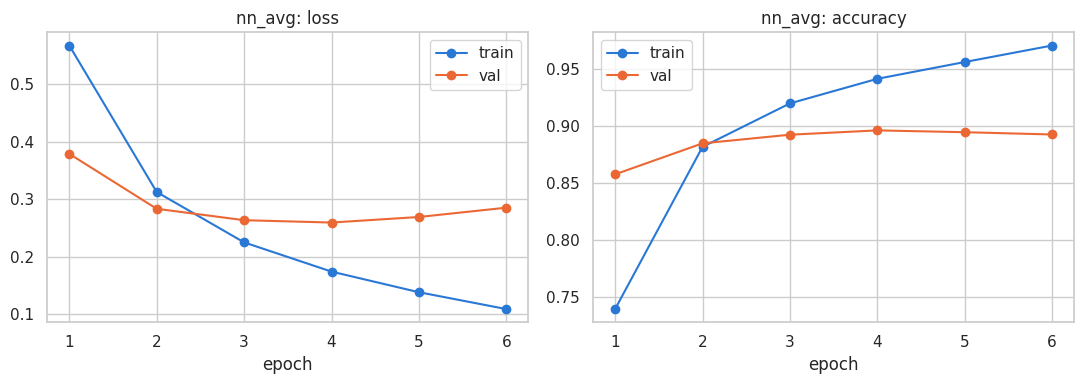

In [42]:
plot_curves(nn_avg_runs[SEED]["history"], "nn_avg")

**Nhận xét.** Grid của `nn_avg` rất ổn định, cả 8 cấu hình đều cho val từ 89,0% đến 89,6%. Các bản 32 unit nhỉnh hơn bản 64 unit một chút nên cấu hình được chọn là 32 unit, dropout 0.5, learning rate 5e-4. Với 3 seed, val vẫn nằm trong khoảng 89,1–89,6%, nên kết quả không phụ thuộc nhiều vào seed. Learning curves cho thấy train accuracy lên tới khoảng 97% còn val dừng quanh 89–90% và val_loss bắt đầu tăng sau epoch 4, tức là mô hình đã overfit nhưng early stopping dừng đúng lúc.

### 6.2 mlp_tfidf: MLP trên TF-IDF

Đây vẫn là mạng neural nhưng đầu vào là TF-IDF giống các mô hình học máy. Đặt cạnh Logistic Regression sẽ thấy thêm một tầng ẩn phi tuyến có giúp được gì không. Tầng Dense cần ma trận dày nên dùng một TF-IDF riêng với 20.000 đặc trưng cho vừa RAM.

Grid: tầng ẩn có 128 hoặc 256 unit, dropout và learning rate như trên.

In [43]:
tfidf_mlp = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, max_features=MLP_FEATURES, sublinear_tf=True, dtype=np.float32)
X_train_mlp = tfidf_mlp.fit_transform(train_df["clean"]).toarray()
X_val_mlp = tfidf_mlp.transform(val_df["clean"]).toarray()
X_test_mlp = tfidf_mlp.transform(test_df["clean"]).toarray()
print(X_train_mlp.shape, X_train_mlp.dtype)

(20000, 20000) float32


In [44]:
def build_mlp(units, dropout, lr):
    model = keras.Sequential([
        keras.Input(shape=(MLP_FEATURES,)),
        layers.Dense(units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="binary_crossentropy", metrics=["accuracy"])
    return model


build_mlp(256, 0.5, 1e-3).summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 256)            │     5,120,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,120,513 (19.53 MB)

 Trainable params: 5,120,513 (19.53 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
mlp_grid = run_grid(build_mlp, [128, 256], X_train_mlp, X_val_mlp)
print(f"Tổng thời gian grid: {mlp_grid['time_s'].sum():.0f}s")
mlp_grid.sort_values("val_acc", ascending=False).round(4)

units=128 dropout=0.3 lr=0.001: val_acc=0.9090 best_epoch=2 time=15s
units=128 dropout=0.3 lr=0.0005: val_acc=0.9080 best_epoch=3 time=16s
units=128 dropout=0.5 lr=0.001: val_acc=0.9090 best_epoch=2 time=14s
units=128 dropout=0.5 lr=0.0005: val_acc=0.9104 best_epoch=4 time=17s
units=256 dropout=0.3 lr=0.001: val_acc=0.9078 best_epoch=1 time=14s
units=256 dropout=0.3 lr=0.0005: val_acc=0.9084 best_epoch=2 time=15s
units=256 dropout=0.5 lr=0.001: val_acc=0.9082 best_epoch=1 time=13s
units=256 dropout=0.5 lr=0.0005: val_acc=0.9086 best_epoch=3 time=17s
Tổng thời gian grid: 121s


,units,dropout,lr,val_acc,best_epoch,n_params,time_s
3,128,0.5,0.0005,0.9104,4,2560257,17.3708
0,128,0.3,0.0010,0.9090,2,2560257,14.9552
2,128,0.5,0.0010,0.9090,2,2560257,14.1695
7,256,0.5,0.0005,0.9086,3,5120513,16.7159
5,256,0.3,0.0005,0.9084,2,5120513,15.2138
6,256,0.5,0.0010,0.9082,1,5120513,13.1594
1,128,0.3,0.0005,0.9080,3,2560257,16.0923
4,256,0.3,0.0010,0.9078,1,5120513,13.5666


In [46]:
mlp_config = pick_best(mlp_grid)
print("Cấu hình chọn:", mlp_config)

mlp_runs = train_seeds(build_mlp, mlp_config, X_train_mlp, X_val_mlp)
nn_models["mlp_tfidf"] = {"runs": mlp_runs, "config": mlp_config, "group": "nn", "x_val": X_val_mlp, "x_test": X_test_mlp}

Cấu hình chọn: {'units': 128, 'dropout': 0.5, 'lr': 0.0005}
seed 42
Epoch 1/15
313/313 - 6s - 18ms/step - accuracy: 0.8482 - loss: 0.4767 - val_accuracy: 0.8942 - val_loss: 0.3089
Epoch 2/15
313/313 - 2s - 5ms/step - accuracy: 0.9226 - loss: 0.2331 - val_accuracy: 0.9066 - val_loss: 0.2382
Epoch 3/15
313/313 - 2s - 5ms/step - accuracy: 0.9495 - loss: 0.1575 - val_accuracy: 0.9090 - val_loss: 0.2230
Epoch 4/15
313/313 - 2s - 5ms/step - accuracy: 0.9696 - loss: 0.1115 - val_accuracy: 0.9104 - val_loss: 0.2221
Epoch 5/15
313/313 - 2s - 5ms/step - accuracy: 0.9837 - loss: 0.0788 - val_accuracy: 0.9082 - val_loss: 0.2287
Epoch 6/15
313/313 - 2s - 5ms/step - accuracy: 0.9914 - loss: 0.0561 - val_accuracy: 0.9036 - val_loss: 0.2391
seed=42: val_acc=0.9104 best_epoch=4 time=17s
seed 43
Epoch 1/15
313/313 - 6s - 18ms/step - accuracy: 0.8383 - loss: 0.4757 - val_accuracy: 0.8950 - val_loss: 0.3080
Epoch 2/15
313/313 - 2s - 5ms/step - accuracy: 0.9244 - loss: 0.2317 - val_accuracy: 0.9074 - val_l

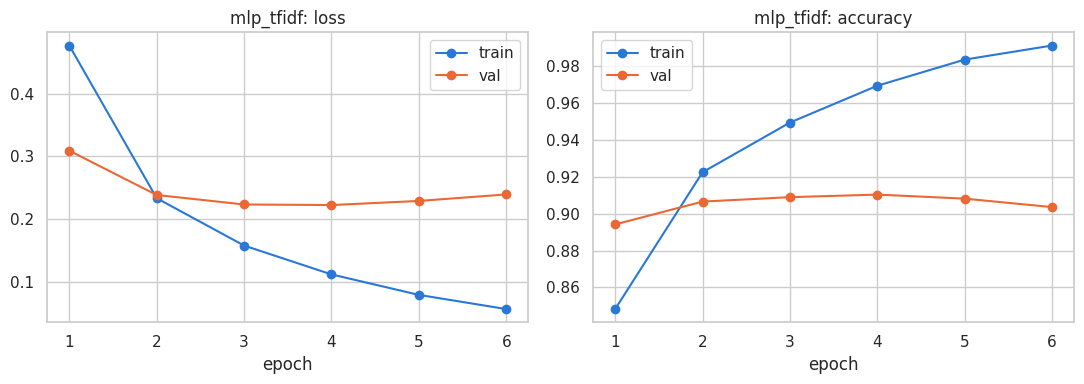

In [47]:
plot_curves(mlp_runs[SEED]["history"], "mlp_tfidf")

**Nhận xét.** Grid của `mlp_tfidf` còn ổn định hơn, val chỉ dao động từ 90,8% đến 91,0%. Cấu hình được chọn là 128 unit, dropout 0.5, learning rate 5e-4, vừa cho val cao nhất vừa chỉ có một nửa số tham số so với bản 256 unit. Ba seed đều đạt khoảng 90,9–91,0%, gần như bằng Logistic Regression trên val. Như vậy thêm một tầng ẩn phi tuyến không giúp được gì, có lẽ vì với TF-IDF thì một ranh giới tuyến tính đã đủ tốt. Train accuracy lên tới khoảng 99% nên mô hình overfit khá mạnh, nhưng nhờ early stopping mà val vẫn giữ được.

## 7. Mạng hồi quy

### 7.1 LSTM

LSTM đọc review lần lượt từng từ và giữ lại một trạng thái ẩn, nên về lý thuyết nó phân biệt được "not good" với "good". Trạng thái ở từ cuối cùng (không tính phần đệm) được đưa qua Dropout rồi tầng Dense để ra xác suất. Không dùng `recurrent_dropout` để LSTM chạy được bằng cuDNN cho nhanh.

Grid: 64 hoặc 128 unit, dropout 0.3 hoặc 0.5, learning rate 1e-3 hoặc 5e-4.

In [48]:
def build_lstm(units, dropout, lr):
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        layers.LSTM(units),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="binary_crossentropy", metrics=["accuracy"])
    return model

Trước khi chạy cả grid, train thử 1 epoch để chắc là mô hình học được (accuracy phải cao hơn hẳn 50%) và xem mỗi epoch mất bao lâu.

In [49]:
keras.utils.set_random_seed(SEED)
trial_model = build_lstm(128, 0.5, 1e-3)
trial_model.summary()

start = time.time()
trial_model.fit(X_train_seq, y_train, validation_data=(X_val_seq, y_val), epochs=1, batch_size=BATCH_SIZE, verbose=2)
print(f"Thời gian 1 epoch: {time.time() - start:.0f}s")

Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_12 (Embedding)        │ (None, 500, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,691,713 (10.27 MB)

 Trainable params: 2,691,713 (10.27 MB)

 Non-trainable params: 0 (0.00 B)

313/313 - 13s - 43ms/step - accuracy: 0.7991 - loss: 0.4453 - val_accuracy: 0.8372 - val_loss: 0.4147
Thời gian 1 epoch: 14s


In [50]:
lstm_grid = run_grid(build_lstm, [64, 128], X_train_seq, X_val_seq)
print(f"Tổng thời gian grid: {lstm_grid['time_s'].sum():.0f}s")
lstm_grid.sort_values("val_acc", ascending=False).round(4)

units=64 dropout=0.3 lr=0.001: val_acc=0.8650 best_epoch=1 time=23s
units=64 dropout=0.3 lr=0.0005: val_acc=0.8812 best_epoch=2 time=29s
units=64 dropout=0.5 lr=0.001: val_acc=0.8736 best_epoch=2 time=30s
units=64 dropout=0.5 lr=0.0005: val_acc=0.8670 best_epoch=1 time=22s
units=128 dropout=0.3 lr=0.001: val_acc=0.8552 best_epoch=4 time=50s
units=128 dropout=0.3 lr=0.0005: val_acc=0.8546 best_epoch=3 time=42s
units=128 dropout=0.5 lr=0.001: val_acc=0.8686 best_epoch=1 time=26s
units=128 dropout=0.5 lr=0.0005: val_acc=0.8776 best_epoch=2 time=34s
Tổng thời gian grid: 255s


,units,dropout,lr,val_acc,best_epoch,n_params,time_s
1,64,0.3,0.0005,0.8812,2,2609473,29.0072
7,128,0.5,0.0005,0.8776,2,2691713,33.9864
2,64,0.5,0.0010,0.8736,2,2609473,29.6230
6,128,0.5,0.0010,0.8686,1,2691713,25.7713
3,64,0.5,0.0005,0.8670,1,2609473,22.4656
0,64,0.3,0.0010,0.8650,1,2609473,22.9367
4,128,0.3,0.0010,0.8552,4,2691713,49.7594
5,128,0.3,0.0005,0.8546,3,2691713,41.7987


In [51]:
lstm_config = pick_best(lstm_grid)
print("Cấu hình chọn:", lstm_config)

Cấu hình chọn: {'units': 64, 'dropout': 0.3, 'lr': 0.0005}


In [52]:
lstm_runs = train_seeds(build_lstm, lstm_config, X_train_seq, X_val_seq)
nn_models["lstm"] = {"runs": lstm_runs, "config": lstm_config, "group": "rnn", "x_val": X_val_seq, "x_test": X_test_seq}

seed 42
Epoch 1/15
313/313 - 9s - 27ms/step - accuracy: 0.7906 - loss: 0.4393 - val_accuracy: 0.8568 - val_loss: 0.3352
Epoch 2/15
313/313 - 7s - 22ms/step - accuracy: 0.9040 - loss: 0.2537 - val_accuracy: 0.8814 - val_loss: 0.3014
Epoch 3/15
313/313 - 7s - 22ms/step - accuracy: 0.9348 - loss: 0.1870 - val_accuracy: 0.8666 - val_loss: 0.3379
Epoch 4/15
313/313 - 7s - 22ms/step - accuracy: 0.9428 - loss: 0.1704 - val_accuracy: 0.8664 - val_loss: 0.3386
seed=42: val_acc=0.8814 best_epoch=2 time=30s
seed 43
Epoch 1/15
313/313 - 9s - 28ms/step - accuracy: 0.7922 - loss: 0.4468 - val_accuracy: 0.8772 - val_loss: 0.3047
Epoch 2/15
313/313 - 7s - 22ms/step - accuracy: 0.9121 - loss: 0.2418 - val_accuracy: 0.8636 - val_loss: 0.3227
Epoch 3/15
313/313 - 7s - 22ms/step - accuracy: 0.9330 - loss: 0.1911 - val_accuracy: 0.8702 - val_loss: 0.3108
seed=43: val_acc=0.8772 best_epoch=1 time=23s
seed 44
Epoch 1/15
313/313 - 9s - 28ms/step - accuracy: 0.7806 - loss: 0.4576 - val_accuracy: 0.8564 - val_l

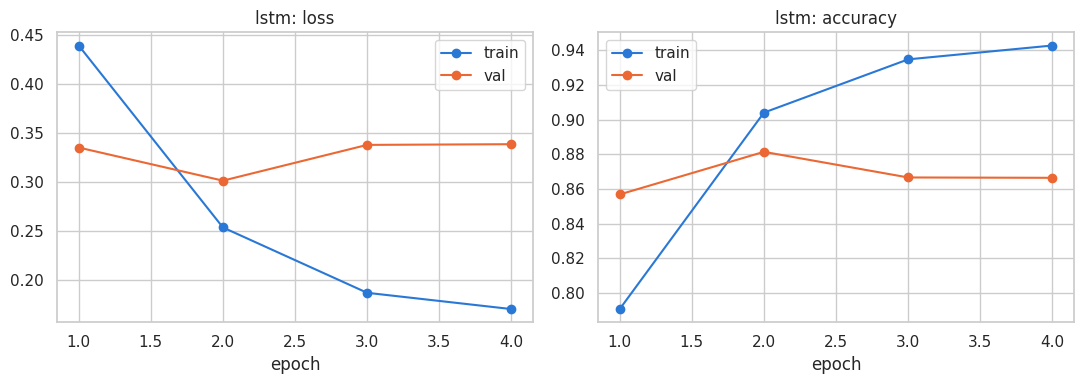

In [53]:
plot_curves(lstm_runs[SEED]["history"], "lstm")

**Nhận xét.** Chạy thử 1 epoch mất 14 giây nên LSTM đã chạy được bằng cuDNN. Khác với `nn_avg`, grid của LSTM dao động mạnh từ 85,5% đến 88,1%, tức là mô hình này nhạy với siêu tham số hơn nhiều. Cấu hình được chọn là 64 unit, dropout 0.3, learning rate 5e-4; với 3 seed, val đạt 87,7–88,1%, thấp hơn `nn_avg` khoảng 1,5 điểm. Epoch tốt nhất chỉ là 1 hoặc 2, và trên learning curves val_loss thấp nhất ở epoch 2 rồi tăng lại trong khi train accuracy vẫn lên tới 94%, nên LSTM overfit rất sớm.

### 7.2 GRU

GRU là bản gọn hơn của LSTM, ít cổng hơn nên ít tham số hơn. Ở đây dùng luôn cấu hình tốt nhất của LSTM để so sánh trực tiếp hai loại cell.

In [54]:
def build_gru(units, dropout, lr):
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        layers.GRU(units),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="binary_crossentropy", metrics=["accuracy"])
    return model


gru_runs = train_seeds(build_gru, lstm_config, X_train_seq, X_val_seq)
nn_models["gru"] = {"runs": gru_runs, "config": lstm_config, "group": "rnn", "x_val": X_val_seq, "x_test": X_test_seq}

seed 42
Epoch 1/15
313/313 - 9s - 28ms/step - accuracy: 0.7636 - loss: 0.4728 - val_accuracy: 0.8638 - val_loss: 0.3257
Epoch 2/15
313/313 - 7s - 21ms/step - accuracy: 0.9033 - loss: 0.2528 - val_accuracy: 0.8588 - val_loss: 0.3531
Epoch 3/15
313/313 - 7s - 21ms/step - accuracy: 0.9324 - loss: 0.1890 - val_accuracy: 0.8536 - val_loss: 0.4397
seed=42: val_acc=0.8638 best_epoch=1 time=22s
seed 43
Epoch 1/15
313/313 - 8s - 27ms/step - accuracy: 0.7684 - loss: 0.4637 - val_accuracy: 0.8662 - val_loss: 0.3257
Epoch 2/15
313/313 - 7s - 21ms/step - accuracy: 0.9026 - loss: 0.2546 - val_accuracy: 0.8780 - val_loss: 0.3078
Epoch 3/15
313/313 - 7s - 21ms/step - accuracy: 0.9345 - loss: 0.1878 - val_accuracy: 0.8774 - val_loss: 0.3360
Epoch 4/15
313/313 - 7s - 22ms/step - accuracy: 0.9453 - loss: 0.1555 - val_accuracy: 0.8774 - val_loss: 0.3358
seed=43: val_acc=0.8780 best_epoch=2 time=29s
seed 44
Epoch 1/15
313/313 - 9s - 30ms/step - accuracy: 0.7497 - loss: 0.4847 - val_accuracy: 0.8672 - val_l

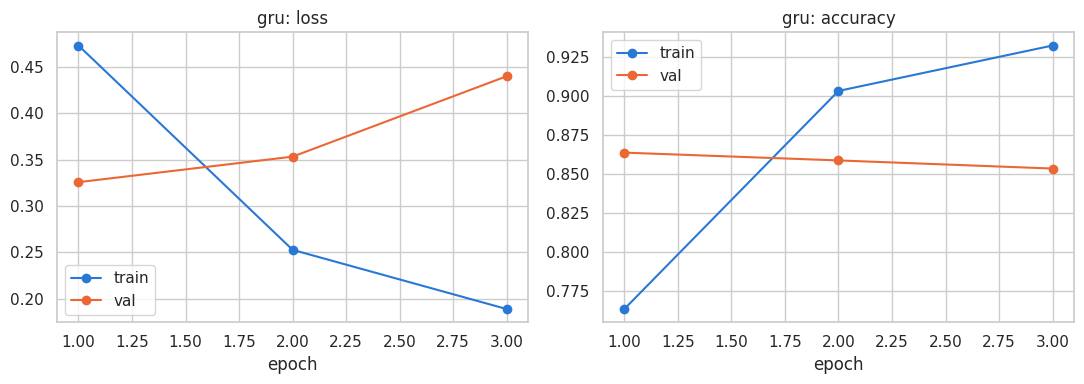

In [55]:
plot_curves(gru_runs[SEED]["history"], "gru")

**Nhận xét.** GRU cho val từ 86,4% đến 87,8% tùy seed, nhìn chung không hơn LSTM. GRU ít cổng hơn nên tầng hồi quy nhỏ hơn, nhưng phần lớn tham số nằm ở embedding nên tổng số tham số và thời gian train gần như bằng LSTM. Trên curve của seed 42, val_loss thấp nhất ngay ở epoch 1 rồi tăng dần, nên GRU cũng overfit rất sớm. Cần nhớ là GRU dùng lại cấu hình của LSTM chứ không được tune riêng, nên có thể chưa phải cấu hình tốt nhất cho nó.

### 7.3 BiLSTM

BiLSTM đọc review theo cả hai chiều, nên phần cuối review cũng được nhìn thấy sớm. Mỗi chiều dùng một nửa số unit của LSTM để tổng kích thước đầu ra bằng nhau, dropout và learning rate giữ nguyên.

In [56]:
def build_bilstm(units, dropout, lr):
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        layers.Bidirectional(layers.LSTM(units)),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="binary_crossentropy", metrics=["accuracy"])
    return model


bilstm_config = {"units": lstm_config["units"] // 2, "dropout": lstm_config["dropout"], "lr": lstm_config["lr"]}
print("Cấu hình BiLSTM:", bilstm_config)

bilstm_runs = train_seeds(build_bilstm, bilstm_config, X_train_seq, X_val_seq)
nn_models["bilstm"] = {"runs": bilstm_runs, "config": bilstm_config, "group": "rnn", "x_val": X_val_seq, "x_test": X_test_seq}

Cấu hình BiLSTM: {'units': 32, 'dropout': 0.3, 'lr': 0.0005}
seed 42
Epoch 1/15
313/313 - 15s - 46ms/step - accuracy: 0.7746 - loss: 0.4599 - val_accuracy: 0.8794 - val_loss: 0.3115
Epoch 2/15
313/313 - 12s - 37ms/step - accuracy: 0.9140 - loss: 0.2269 - val_accuracy: 0.8732 - val_loss: 0.3194
Epoch 3/15
313/313 - 12s - 37ms/step - accuracy: 0.9423 - loss: 0.1632 - val_accuracy: 0.8478 - val_loss: 0.4395
seed=42: val_acc=0.8794 best_epoch=1 time=38s
seed 43
Epoch 1/15
313/313 - 14s - 46ms/step - accuracy: 0.7713 - loss: 0.4690 - val_accuracy: 0.8782 - val_loss: 0.3153
Epoch 2/15
313/313 - 11s - 36ms/step - accuracy: 0.9099 - loss: 0.2365 - val_accuracy: 0.8844 - val_loss: 0.3172
Epoch 3/15
313/313 - 12s - 37ms/step - accuracy: 0.9438 - loss: 0.1618 - val_accuracy: 0.8708 - val_loss: 0.3702
seed=43: val_acc=0.8782 best_epoch=1 time=37s
seed 44
Epoch 1/15
313/313 - 14s - 45ms/step - accuracy: 0.7745 - loss: 0.4664 - val_accuracy: 0.8692 - val_loss: 0.3147
Epoch 2/15
313/313 - 12s - 37ms/

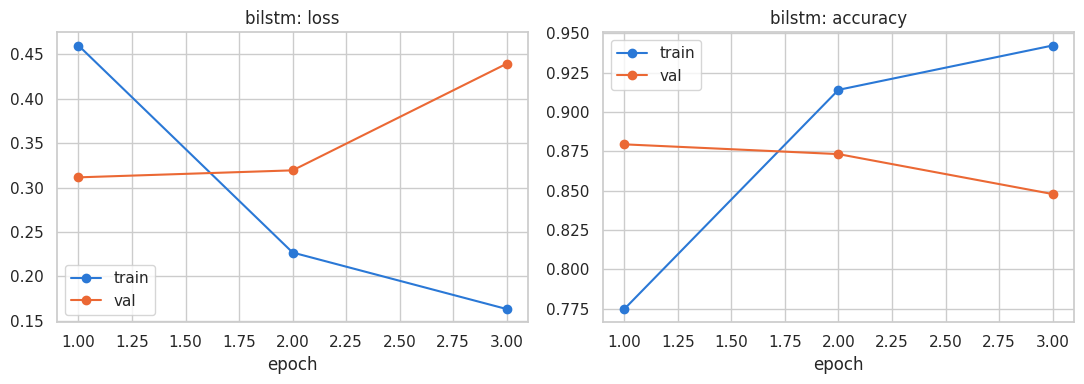

In [57]:
plot_curves(bilstm_runs[SEED]["history"], "bilstm")

**Nhận xét.** BiLSTM với 32 unit mỗi chiều cho val từ 87,8% đến 88,7%. Seed 44 đạt 88,7%, cao nhất trong nhóm hồi quy, nhưng hai seed còn lại chỉ ngang LSTM, nên chưa thể nói việc đọc thêm chiều ngược lại giúp ích rõ rệt. Đổi lại thời gian train lâu hơn hẳn, 37–49 giây so với 23–30 giây của LSTM. Epoch tốt nhất vẫn chỉ là 1 hoặc 2, tức là BiLSTM cũng overfit sớm như LSTM.

### 7.4 LSTM + GloVe

Thay vì học embedding từ đầu với 20.000 review, có thể dùng GloVe 100 chiều đã được học sẵn trên Wikipedia và Gigaword. Thử hai cách: cho embedding học tiếp cùng mô hình (`lstm_glove`) và giữ nguyên không cho học (`lstm_glove_frozen`). Phần LSTM dùng lại cấu hình tốt nhất ở 7.1.

Trên Kaggle thì thêm dataset GloVe qua Add Input. Nếu không có, notebook sẽ tự tải file từ trang của Stanford, khoảng 800 MB.

In [58]:
glove_files = glob.glob("/kaggle/input/**/glove.6B.100d.txt", recursive=True)

if len(glove_files) > 0:
    glove_path = glove_files[0]
else:
    urllib.request.urlretrieve("https://nlp.stanford.edu/data/glove.6B.zip", "/tmp/glove.6B.zip")
    with zipfile.ZipFile("/tmp/glove.6B.zip") as zf:
        zf.extract("glove.6B.100d.txt", "/tmp")
    glove_path = "/tmp/glove.6B.100d.txt"

print(glove_path)

/kaggle/input/datasets/rtatman/glove-global-vectors-for-word-representation/glove.6B.100d.txt


In [59]:
word_index = {}
for i, word in enumerate(vocab):
    word_index[word] = i

glove_matrix = np.zeros((VOCAB_SIZE, GLOVE_DIM), dtype="float32")
found = 0
with open(glove_path, encoding="utf8") as f:
    for line in f:
        parts = line.rstrip().split(" ")
        word = parts[0]
        if word in word_index:
            glove_matrix[word_index[word]] = np.array(parts[1:], dtype="float32")
            found += 1

print(f"Có vector GloVe cho {found}/{len(vocab)} từ trong vocab ({found / len(vocab):.1%})")

Có vector GloVe cho 19151/20000 từ trong vocab (95.8%)


In [60]:
def build_lstm_glove(units, dropout, lr, trainable):
    embedding = layers.Embedding(VOCAB_SIZE, GLOVE_DIM, mask_zero=True, trainable=trainable)
    model = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        embedding,
        layers.LSTM(units),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),
    ])
    embedding.set_weights([glove_matrix])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="binary_crossentropy", metrics=["accuracy"])
    return model


glove_config = {"units": lstm_config["units"], "dropout": lstm_config["dropout"], "lr": lstm_config["lr"], "trainable": True}
glove_frozen_config = {"units": lstm_config["units"], "dropout": lstm_config["dropout"], "lr": lstm_config["lr"], "trainable": False}

seed 42
Epoch 1/15
313/313 - 9s - 27ms/step - accuracy: 0.7369 - loss: 0.5311 - val_accuracy: 0.8220 - val_loss: 0.4083
Epoch 2/15
313/313 - 7s - 21ms/step - accuracy: 0.8416 - loss: 0.3794 - val_accuracy: 0.8580 - val_loss: 0.3467
Epoch 3/15
313/313 - 7s - 21ms/step - accuracy: 0.8814 - loss: 0.3029 - val_accuracy: 0.8648 - val_loss: 0.3489
Epoch 4/15
313/313 - 7s - 21ms/step - accuracy: 0.9033 - loss: 0.2634 - val_accuracy: 0.8662 - val_loss: 0.3747
seed=42: val_acc=0.8580 best_epoch=2 time=29s
seed 43
Epoch 1/15
313/313 - 9s - 27ms/step - accuracy: 0.7046 - loss: 0.5584 - val_accuracy: 0.8172 - val_loss: 0.4227
Epoch 2/15
313/313 - 7s - 21ms/step - accuracy: 0.8351 - loss: 0.3907 - val_accuracy: 0.8546 - val_loss: 0.3563
Epoch 3/15
313/313 - 7s - 21ms/step - accuracy: 0.8657 - loss: 0.3341 - val_accuracy: 0.8250 - val_loss: 0.4041
Epoch 4/15
313/313 - 7s - 21ms/step - accuracy: 0.9017 - loss: 0.2644 - val_accuracy: 0.8552 - val_loss: 0.3424
Epoch 5/15
313/313 - 7s - 21ms/step - accu

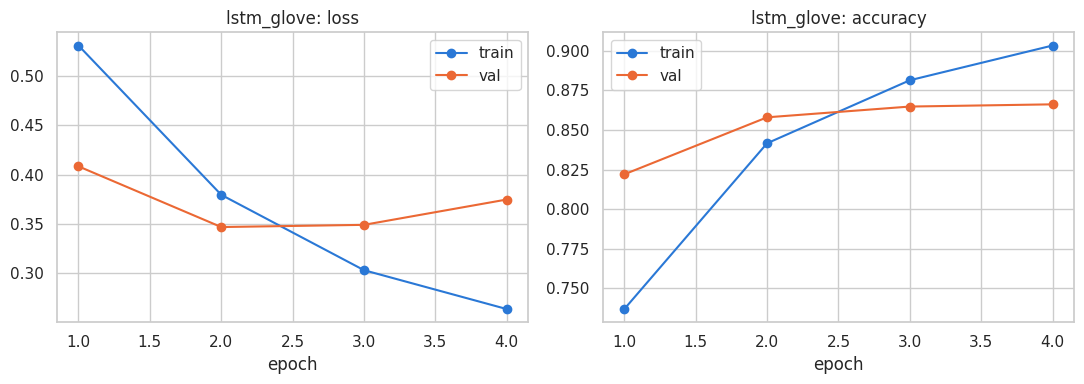

In [61]:
glove_runs = train_seeds(build_lstm_glove, glove_config, X_train_seq, X_val_seq)
nn_models["lstm_glove"] = {"runs": glove_runs, "config": glove_config, "group": "rnn", "x_val": X_val_seq, "x_test": X_test_seq}
plot_curves(glove_runs[SEED]["history"], "lstm_glove")

seed 42
Epoch 1/15
313/313 - 8s - 26ms/step - accuracy: 0.7176 - loss: 0.5574 - val_accuracy: 0.7666 - val_loss: 0.5090
Epoch 2/15
313/313 - 6s - 20ms/step - accuracy: 0.7723 - loss: 0.4937 - val_accuracy: 0.7302 - val_loss: 0.5620
Epoch 3/15
313/313 - 6s - 20ms/step - accuracy: 0.7947 - loss: 0.4558 - val_accuracy: 0.8118 - val_loss: 0.4297
Epoch 4/15
313/313 - 6s - 20ms/step - accuracy: 0.8053 - loss: 0.4387 - val_accuracy: 0.8310 - val_loss: 0.4020
Epoch 5/15
313/313 - 6s - 20ms/step - accuracy: 0.8194 - loss: 0.4174 - val_accuracy: 0.8320 - val_loss: 0.3952
Epoch 6/15
313/313 - 6s - 20ms/step - accuracy: 0.8285 - loss: 0.4034 - val_accuracy: 0.8388 - val_loss: 0.3812
Epoch 7/15
313/313 - 6s - 20ms/step - accuracy: 0.8445 - loss: 0.3690 - val_accuracy: 0.8552 - val_loss: 0.3575
Epoch 8/15
313/313 - 6s - 20ms/step - accuracy: 0.8516 - loss: 0.3560 - val_accuracy: 0.8524 - val_loss: 0.3740
Epoch 9/15
313/313 - 6s - 20ms/step - accuracy: 0.8594 - loss: 0.3422 - val_accuracy: 0.8658 - v

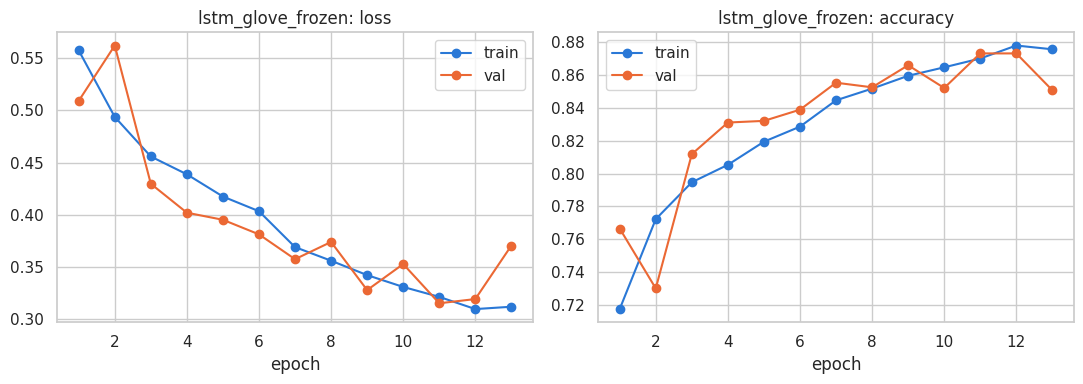

In [62]:
glove_frozen_runs = train_seeds(build_lstm_glove, glove_frozen_config, X_train_seq, X_val_seq)
nn_models["lstm_glove_frozen"] = {"runs": glove_frozen_runs, "config": glove_frozen_config, "group": "rnn", "x_val": X_val_seq, "x_test": X_test_seq}
plot_curves(glove_frozen_runs[SEED]["history"], "lstm_glove_frozen")

**Nhận xét.** GloVe phủ được 95,8% vocab, nhưng bản fine-tune chỉ cho val từ 85,8% đến 87,9%, không hơn LSTM học embedding từ đầu. Bản đóng băng học chậm nhưng đều: seed 42 và 43 đạt 87,3% và 87,4% ở epoch 11 và 13, gần bằng LSTM thường, và trên curve hai đường train và val bám sát nhau nên ít overfit hơn hẳn. Riêng seed 44 dừng ngay ở epoch 3 với val 80,0%. Bản này vốn cần nhiều epoch và val_loss dao động mạnh ở mấy epoch đầu, nên early stopping với patience 2 đã dừng quá sớm; đây là điểm yếu của cách đặt early stopping chứ không hẳn của mô hình.

## 8. Đánh giá trên tập test

Đến đây mọi cấu hình đã được chốt bằng val, giờ mới dùng tới tập test và dùng chung cho tất cả mô hình. Sau phần này không sửa gì thêm ở mô hình hay tiền xử lý, các phân tích phía sau chỉ để hiểu kết quả.

Ngưỡng phân loại cố định 0.5, riêng SVM là 0. Thời gian dự đoán chỉ tính phần predict, và mạng neural được chạy thử một lần trước khi đo để không tính thời gian khởi tạo. Học máy chạy trên CPU còn mạng neural chạy trên GPU, nên so thời gian giữa hai nhóm chỉ để tham khảo.

In [63]:
rows = []
test_scores = {}
test_preds = {}

for name in ml_models:
    info = ml_models[name]
    start = time.time()
    if name == "svm":
        scores = info["model"].decision_function(X_test_tfidf)
        threshold = 0
    else:
        scores = info["model"].predict_proba(X_test_tfidf)[:, 1]
        threshold = 0.5
    infer_time = time.time() - start

    row = {"model": name, "group": "ml", "seed": SEED}
    row.update(evaluate(y_test, scores, threshold))
    row.update({
        "train_time_s": info["train_time"],
        "infer_time_s": infer_time,
        "n_params": info["n_params"],
        "best_epoch": None,
        "device": "cpu",
        "params": info["params"],
    })
    rows.append(row)
    test_scores[(name, SEED)] = scores
    test_preds[(name, SEED)] = (scores > threshold).astype(int)

In [64]:
for name in nn_models:
    info = nn_models[name]
    params = " ".join(f"{key}={value}" for key, value in info["config"].items())
    for seed in SEEDS:
        run = info["runs"][seed]
        run["model"].predict(info["x_val"][:512], batch_size=512, verbose=0)
        start = time.time()
        scores = run["model"].predict(info["x_test"], batch_size=512, verbose=0).ravel()
        infer_time = time.time() - start

        row = {"model": name, "group": info["group"], "seed": seed}
        row.update(evaluate(y_test, scores, 0.5))
        row.update({
            "train_time_s": run["train_time"],
            "infer_time_s": infer_time,
            "n_params": run["model"].count_params(),
            "best_epoch": run["best_epoch"],
            "device": DEVICE,
            "params": params,
        })
        rows.append(row)
        test_scores[(name, seed)] = scores
        test_preds[(name, seed)] = (scores > 0.5).astype(int)

In [65]:
results_df = pd.DataFrame(rows)
results_df.to_csv(f"{RESULTS_DIR}/results.csv", index=False)
results_df.round(4)

,model,group,seed,accuracy,precision,recall,f1,roc_auc,train_time_s,infer_time_s,n_params,best_epoch,device,params
0,lr,ml,42,0.9031,0.9030,0.9032,0.9031,0.9653,2.7315,0.0210,100001,NaN,cpu,C=10
1,svm,ml,42,0.9015,0.9022,0.9007,0.9014,0.9645,0.7430,0.0207,100001,NaN,cpu,C=1
2,nb,ml,42,0.8692,0.8843,0.8495,0.8665,0.9431,0.0379,0.0423,200002,NaN,cpu,alpha=0.1
3,nn_avg,nn,42,0.8815,0.8875,0.8738,0.8806,0.9515,13.7083,0.7743,2564161,4.0,gpu,units=32 dropout=0.5 lr=0.0005
4,nn_avg,nn,43,0.8812,0.8803,0.8823,0.8813,0.9510,13.7898,0.7153,2564161,4.0,gpu,units=32 dropout=0.5 lr=0.0005
5,nn_avg,nn,44,0.8731,0.9207,0.8166,0.8655,0.9518,12.3171,0.6941,2564161,3.0,gpu,units=32 dropout=0.5 lr=0.0005
6,mlp_tfidf,nn,42,0.8996,0.8995,0.8997,0.8996,0.9643,17.4436,6.0503,2560257,4.0,gpu,units=128 dropout=0.5 lr=0.0005
7,mlp_tfidf,nn,43,0.9008,0.8923,0.9118,0.9019,0.9644,17.4012,5.7708,2560257,4.0,gpu,units=128 dropout=0.5 lr=0.0005
8,mlp_tfidf,nn,44,0.9000,0.8999,0.9002,0.9000,0.9642,17.4139,5.8215,2560257,4.0,gpu,units=128 dropout=0.5 lr=0.0005
9,lstm,rnn,42,0.8721,0.8711,0.8734,0.8723,0.9405,29.6253,1.1504,2609473,2.0,gpu,units=64 dropout=0.3 lr=0.0005


## 9. So sánh các mô hình

### 9.1 Bảng tổng hợp

Với mạng neural, kết quả là trung bình ± độ lệch chuẩn của 3 seed. Mô hình học máy chỉ chạy một lần vì kết quả không phụ thuộc vào seed.

In [66]:
summary = results_df.groupby("model")[["accuracy", "f1", "roc_auc", "train_time_s", "infer_time_s", "n_params"]].agg(["mean", "std"])
summary = summary.sort_values(("accuracy", "mean"), ascending=False)

table = pd.DataFrame(index=summary.index)
table["group"] = results_df.groupby("model")["group"].first()
for metric in ["accuracy", "f1", "roc_auc"]:
    texts = []
    for name in summary.index:
        mean = summary.loc[name, (metric, "mean")]
        std = summary.loc[name, (metric, "std")]
        if np.isnan(std):
            texts.append(f"{mean:.4f}")
        else:
            texts.append(f"{mean:.4f} ± {std:.4f}")
    table[metric] = texts
table["train_time_s"] = summary[("train_time_s", "mean")].round(1)
table["infer_time_s"] = summary[("infer_time_s", "mean")].round(2)
table["n_params"] = summary[("n_params", "mean")].astype(int)

table.to_csv(f"{RESULTS_DIR}/summary.csv")
table

,group,accuracy,f1,roc_auc,train_time_s,infer_time_s,n_params
model,,,,,,,
lr,ml,0.9031,0.9031,0.9653,2.7,0.02,100001
svm,ml,0.9015,0.9014,0.9645,0.7,0.02,100001
mlp_tfidf,nn,0.9001 ± 0.0006,0.9005 ± 0.0012,0.9643 ± 0.0001,17.4,5.88,2560257
nn_avg,nn,0.8786 ± 0.0048,0.8758 ± 0.0089,0.9515 ± 0.0004,13.3,0.73,2564161
nb,ml,0.8692,0.8665,0.9431,0.0,0.04,200002
lstm,rnn,0.8678 ± 0.0043,0.8667 ± 0.0064,0.9392 ± 0.0013,27.3,1.08,2609473
bilstm,rnn,0.8647 ± 0.0095,0.8580 ± 0.0133,0.9419 ± 0.0042,41.5,1.55,2601281
lstm_glove,rnn,0.8625 ± 0.0113,0.8649 ± 0.0118,0.9369 ± 0.0114,44.6,1.05,2042305
gru,rnn,0.8610 ± 0.0052,0.8578 ± 0.0099,0.9359 ± 0.0018,27.1,1.01,2597313


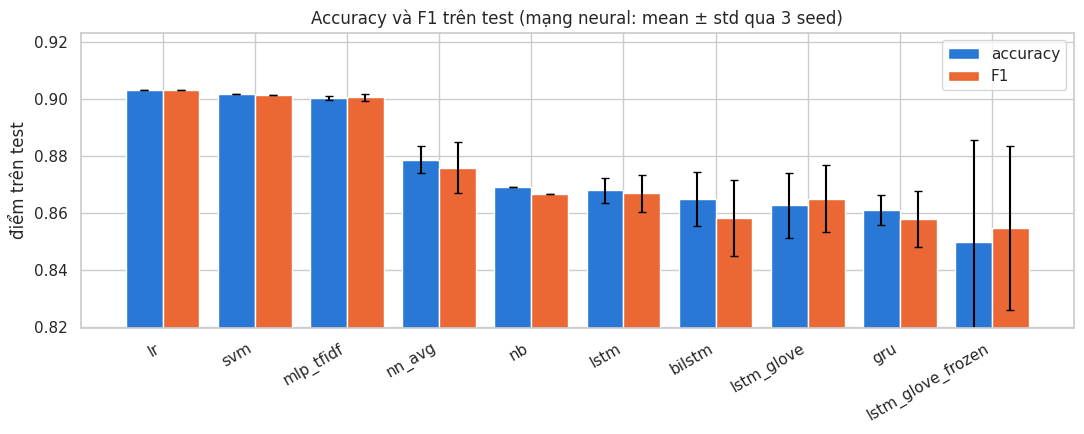

In [67]:
x = np.arange(len(summary))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - 0.2, summary[("accuracy", "mean")], width=0.4, yerr=summary[("accuracy", "std")].fillna(0), capsize=3, label="accuracy")
ax.bar(x + 0.2, summary[("f1", "mean")], width=0.4, yerr=summary[("f1", "std")].fillna(0), capsize=3, label="F1")
ax.set_xticks(x)
ax.set_xticklabels(summary.index, rotation=30, ha="right")
low = min(summary[("accuracy", "mean")].min(), summary[("f1", "mean")].min())
high = max(summary[("accuracy", "mean")].max(), summary[("f1", "mean")].max())
ax.set_ylim(low - 0.03, high + 0.02)
ax.set_ylabel("điểm trên test")
ax.set_title("Accuracy và F1 trên test (mạng neural: mean ± std qua 3 seed)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/compare_bar.png", dpi=150)
plt.show()

### 9.2 ROC và confusion matrix

Các hình này vẽ cho seed 42. ROC chỉ vẽ 8 mô hình cho đỡ rối, AUC của tất cả mô hình đã có trong bảng ở trên.

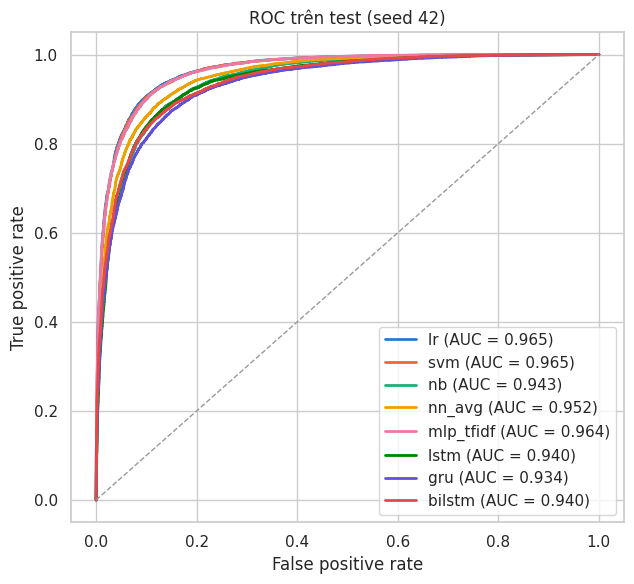

In [68]:
roc_models = ["lr", "svm", "nb", "nn_avg", "mlp_tfidf", "lstm", "gru", "bilstm"]
MODEL_COLORS = dict(zip(roc_models, PALETTE))

plt.figure(figsize=(6.5, 6))
for name in roc_models:
    fpr, tpr, _ = roc_curve(y_test, test_scores[(name, SEED)])
    auc = roc_auc_score(y_test, test_scores[(name, SEED)])
    plt.plot(fpr, tpr, linewidth=2, color=MODEL_COLORS[name], label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC trên test (seed 42)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/roc_all.png", dpi=150)
plt.show()

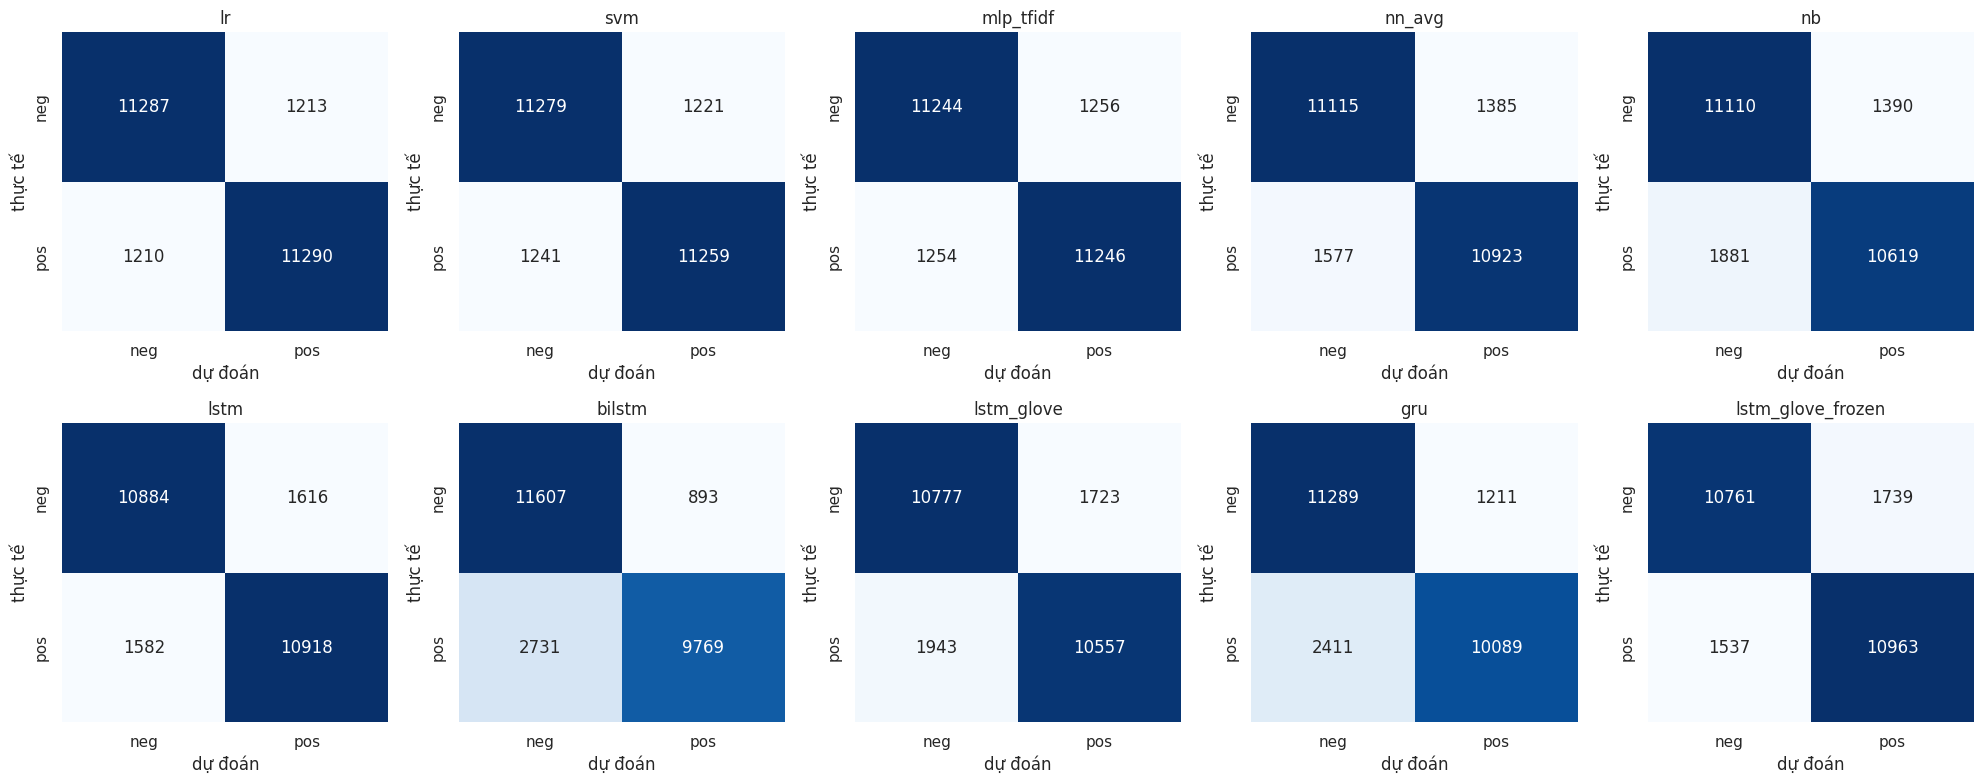

In [69]:
model_names = list(summary.index)
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, name in zip(axes.ravel(), model_names):
    cm = confusion_matrix(y_test, test_preds[(name, SEED)])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    ax.set_title(name)
    ax.set_xlabel("dự đoán")
    ax.set_ylabel("thực tế")
for ax in axes.ravel()[len(model_names):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/cm_all.png", dpi=150)
plt.show()

### 9.3 Chi phí so với độ chính xác

Trục ngang là thời gian train, chia theo thang log. Nhớ là học máy train trên CPU, còn mạng neural train trên GPU.

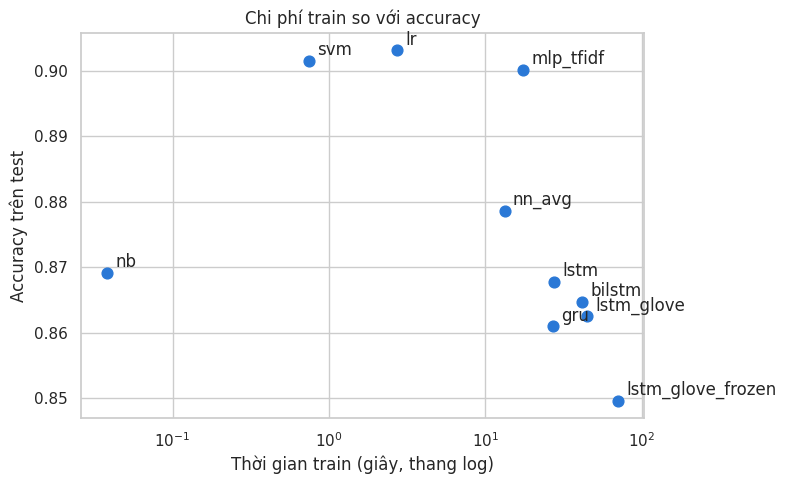

In [70]:
plt.figure(figsize=(8, 5))
for name in summary.index:
    train_time = summary.loc[name, ("train_time_s", "mean")]
    acc = summary.loc[name, ("accuracy", "mean")]
    plt.scatter(train_time, acc, s=60, color=PALETTE[0])
    plt.annotate(name, (train_time, acc), textcoords="offset points", xytext=(6, 4))
plt.xscale("log")
plt.xlabel("Thời gian train (giây, thang log)")
plt.ylabel("Accuracy trên test")
plt.title("Chi phí train so với accuracy")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/cost_vs_acc.png", dpi=150)
plt.show()

### 9.4 Kiểm định McNemar

Chênh nhau vài phần nghìn accuracy chưa chắc đã là chênh thật. Kiểm định McNemar chỉ nhìn vào những review mà hai mô hình đoán khác nhau: nếu hai mô hình ngang nhau thì số lần A đúng mà B sai phải xấp xỉ số lần ngược lại. Ở đây kiểm định bằng phép thử nhị thức với xác suất 0.5, mức ý nghĩa 0,05, dùng seed 42.

In [71]:
pairs = [
    ("lstm", "lr"),
    ("lstm", "svm"),
    ("lstm", "nn_avg"),
    ("lstm", "mlp_tfidf"),
    ("gru", "lstm"),
    ("bilstm", "lstm"),
    ("lstm_glove", "lstm"),
]

mcnemar_rows = []
for model_a, model_b in pairs:
    correct_a = test_preds[(model_a, SEED)] == y_test
    correct_b = test_preds[(model_b, SEED)] == y_test
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    p_value = binomtest(b, b + c, 0.5).pvalue
    mcnemar_rows.append({"A": model_a, "B": model_b, "A đúng, B sai": b, "A sai, B đúng": c, "p_value": p_value})

pd.DataFrame(mcnemar_rows).round(4)

,A,B,"A đúng, B sai","A sai, B đúng",p_value
0,lstm,lr,746,1521,0.0
1,lstm,svm,793,1529,0.0
2,lstm,nn_avg,783,1019,0.0
3,lstm,mlp_tfidf,866,1554,0.0
4,gru,lstm,1000,1424,0.0
5,bilstm,lstm,1126,1552,0.0
6,lstm_glove,lstm,1258,1726,0.0


**Nhận xét.** Logistic Regression đứng đầu với 90,3%, SVM và `mlp_tfidf` bám sát quanh 90%, sau đó là `nn_avg` với 87,9% và Naive Bayes với 86,9%. LSTM chỉ đạt 86,8%, các biến thể hồi quy khác nằm trong khoảng 85–86,5%, riêng GloVe đóng băng có độ lệch chuẩn tới 3,6 điểm vì một seed tụt còn 80,8%. ROC-AUC cũng xếp theo thứ tự tương tự, khoảng 0,965 với LR, SVM, MLP so với 0,94 của LSTM. Confusion matrix cho thấy GRU và BiLSTM ở seed 42 nghiêng hẳn về negative, bỏ sót lần lượt 2.411 và 2.731 review positive. Về chi phí, LR train 2,7 giây trên CPU với 100 nghìn tham số, còn LSTM mất 27 giây trên GPU với 2,6 triệu tham số mà vẫn kém hơn.

McNemar xác nhận LSTM thua LR có ý nghĩa thống kê: có 1.521 review LR đúng mà LSTM sai, chiều ngược lại chỉ 746, p gần bằng 0, và kết quả tương tự khi so với SVM, `nn_avg` và `mlp_tfidf`. Các cặp giữa những mô hình hồi quy cũng ra p gần 0, nhưng phép thử chỉ dùng seed 42, mà chênh lệch trung bình giữa chúng còn nhỏ hơn độ dao động giữa các seed, nên không thể kết luận mô hình hồi quy nào tốt hơn.

## 10. Phân tích

### 10.1 Accuracy theo độ dài review

Chia tập test thành 4 nhóm theo số token: ngắn (dưới Q1), trung bình (Q1 đến Q3), dài (Q3 đến `MAX_LEN`) và bị cắt (dài hơn `MAX_LEN`). Q1 và Q3 lấy từ train. Nhóm bị cắt là chỗ đáng xem nhất, vì mạng neural chỉ thấy phần đầu của review, còn TF-IDF thì thấy hết.

In [72]:
q1 = train_df["n_tokens"].quantile(0.25)
q3 = train_df["n_tokens"].quantile(0.75)
print("Q1 =", q1, "| Q3 =", q3, "| MAX_LEN =", MAX_LEN)

length_group = pd.cut(test_df["n_tokens"], bins=[0, q1, q3, MAX_LEN, np.inf], labels=["ngắn", "trung bình", "dài", "bị cắt"])
print(length_group.value_counts().sort_index())

Q1 = 128.0 | Q3 = 284.0 | MAX_LEN = 500
n_tokens
ngắn           6539
trung bình    12419
dài            4138
bị cắt         1904
Name: count, dtype: int64


In [73]:
length_df = pd.DataFrame({"group": length_group})
for name in model_names:
    length_df[name] = test_preds[(name, SEED)] == y_test

acc_by_length = length_df.groupby("group", observed=True).mean()
acc_by_length.round(4)

,lr,svm,mlp_tfidf,nn_avg,nb,lstm,bilstm,lstm_glove,gru,lstm_glove_frozen
group,,,,,,,,,,
ngắn,0.9050,0.9032,0.9027,0.8897,0.8786,0.8832,0.8683,0.8663,0.8679,0.8744
trung bình,0.9032,0.9013,0.8990,0.8831,0.8679,0.8762,0.8605,0.8578,0.8590,0.8735
dài,0.9007,0.8992,0.8968,0.8794,0.8623,0.8697,0.8461,0.8463,0.8473,0.8625
bị cắt,0.9007,0.9023,0.8986,0.8477,0.8603,0.8120,0.7931,0.7952,0.8030,0.8346


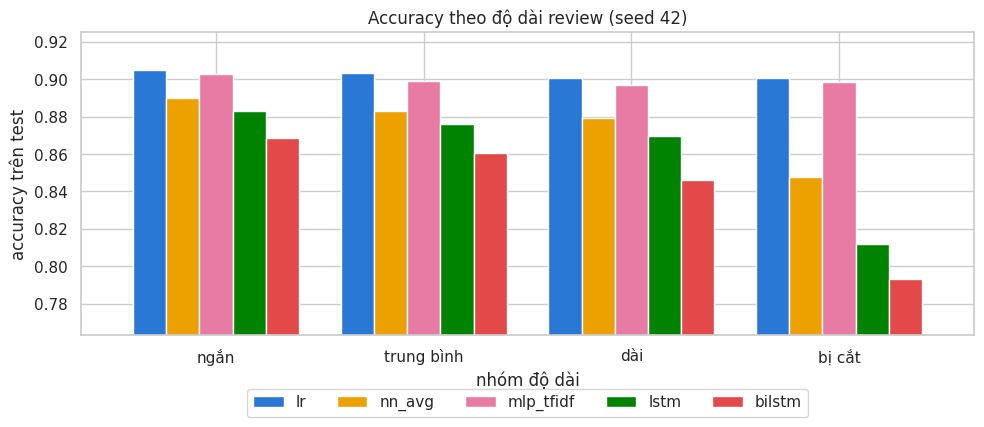

In [74]:
plot_models = ["lr", "nn_avg", "mlp_tfidf", "lstm", "bilstm"]
ax = acc_by_length[plot_models].plot(kind="bar", figsize=(10, 4.5), width=0.8, color=[MODEL_COLORS[name] for name in plot_models])
ax.set_xlabel("nhóm độ dài")
ax.set_ylabel("accuracy trên test")
ax.set_ylim(acc_by_length[plot_models].min().min() - 0.03, acc_by_length[plot_models].max().max() + 0.02)
ax.set_title("Accuracy theo độ dài review (seed 42)")
ax.tick_params(axis="x", rotation=0)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/acc_by_length.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét.** Nhóm bị cắt có 1.904 review, chiếm 7,6% tập test. LR, SVM và `mlp_tfidf` gần như đi ngang quanh 90% ở cả 4 nhóm, vì TF-IDF luôn đọc toàn bộ review. Các mô hình đọc chuỗi thì giảm dần khi review dài ra và tụt mạnh ở nhóm bị cắt: LSTM từ 88,3% xuống 81,2%, BiLSTM từ 86,8% xuống 79,3%, `nn_avg` từ 89,0% xuống 84,8%. Lý do là chúng chỉ thấy 500 token đầu nên mất luôn phần cuối review, mà phần cuối thường là chỗ người viết chốt lại ý kiến.

### 10.2 Thứ tự từ có quan trọng không?

Thử xáo trộn thứ tự các từ trong mỗi review test rồi cho các mô hình dự đoán lại. Review vẫn giữ đủ các từ, chỉ mất thứ tự. `nn_avg` lấy trung bình nên gần như không bị ảnh hưởng, dùng làm đối chứng. Nếu LSTM thật sự dựa vào thứ tự từ thì accuracy của nó phải giảm rõ.

In [75]:
rng = np.random.default_rng(SEED)
X_test_shuffled = X_test_seq.copy()
for i in range(len(X_test_shuffled)):
    n_tokens = np.count_nonzero(X_test_shuffled[i])
    rng.shuffle(X_test_shuffled[i, :n_tokens])

print(X_test_seq[0][:15])
print(X_test_shuffled[0][:15])

[  10  114  938  946    3  236 1692    6  266   56   17    4  169  938
  946]
[   1    3  167 3120 1404  946   43   43    3 3437  704  924  938  228
    1]


In [76]:
shuffle_rows = []
for name in ["nn_avg", "lstm", "gru", "bilstm", "lstm_glove", "lstm_glove_frozen"]:
    model = nn_models[name]["runs"][SEED]["model"]
    shuffled_scores = model.predict(X_test_shuffled, batch_size=512, verbose=0).ravel()
    acc_original = accuracy_score(y_test, test_preds[(name, SEED)])
    acc_shuffled = accuracy_score(y_test, (shuffled_scores > 0.5).astype(int))
    shuffle_rows.append({
        "model": name,
        "acc_original": acc_original,
        "acc_shuffled": acc_shuffled,
        "giảm": acc_original - acc_shuffled,
    })

pd.DataFrame(shuffle_rows).round(4)

,model,acc_original,acc_shuffled,giảm
0,nn_avg,0.8815,0.8815,0.0000
1,lstm,0.8721,0.8668,0.0053
2,gru,0.8551,0.8566,-0.0015
3,bilstm,0.8550,0.8551,-0.0000
4,lstm_glove,0.8534,0.8509,0.0025
5,lstm_glove_frozen,0.8690,0.8360,0.0330


**Nhận xét.** Sau khi xáo trộn, accuracy của `nn_avg` giữ nguyên 88,2%, đúng như dự đoán nên phép đối chứng là hợp lệ. Điều bất ngờ là LSTM chỉ giảm 0,5 điểm, từ 87,2% xuống 86,7%, còn GRU, BiLSTM và `lstm_glove` gần như không đổi. Như vậy LSTM học embedding từ đầu trên 20.000 review gần như không dùng đến thứ tự từ, về bản chất nó đang hoạt động như một mô hình túi từ. Chỉ `lstm_glove_frozen` giảm rõ 3,3 điểm, có lẽ vì khi embedding bị đóng băng thì phần LSTM phải tự gánh nhiều hơn nên mới thật sự dựa vào thứ tự.

### 10.3 Phân tích lỗi

Xem LSTM (seed 42) hay sai ở những review nào và so với Logistic Regression. Trước tiên so xem trong các review LSTM đoán sai, tỉ lệ review có "not", có "but" hay bị cắt có cao hơn bình thường không.

In [77]:
lstm_pred = test_preds[("lstm", SEED)]
lr_pred = test_preds[("lr", SEED)]
lstm_scores = test_scores[("lstm", SEED)]
lr_scores = test_scores[("lr", SEED)]

lstm_wrong = np.where(lstm_pred != y_test)[0]
print("Số review LSTM đoán sai:", len(lstm_wrong))

has_not = test_df["clean"].str.contains(r"\bnot\b")
has_but = test_df["clean"].str.contains(r"\bbut\b")
is_cut = test_df["n_tokens"] > MAX_LEN

print(f"Có 'not': {has_not.mean():.1%} trong toàn test, {has_not.iloc[lstm_wrong].mean():.1%} trong lỗi của LSTM")
print(f"Có 'but': {has_but.mean():.1%} trong toàn test, {has_but.iloc[lstm_wrong].mean():.1%} trong lỗi của LSTM")
print(f"Bị cắt:   {is_cut.mean():.1%} trong toàn test, {is_cut.iloc[lstm_wrong].mean():.1%} trong lỗi của LSTM")

Số review LSTM đoán sai: 3198
Có 'not': 81.2% trong toàn test, 82.5% trong lỗi của LSTM
Có 'but': 71.2% trong toàn test, 75.7% trong lỗi của LSTM
Bị cắt:   7.6% trong toàn test, 11.2% trong lỗi của LSTM


In [78]:
def show_review(i):
    print(f"#{i} | nhãn: {y_test[i]} | lstm: {lstm_scores[i]:.2f} | lr: {lr_scores[i]:.2f} | {test_df['n_tokens'][i]} token")
    print(test_df["text"][i][:700])
    print()


rng = np.random.default_rng(SEED)
for i in rng.choice(lstm_wrong, 8, replace=False):
    show_review(i)

#2062 | nhãn: 0 | lstm: 0.90 | lr: 0.91 | 168 token
In the early 1990's "Step-by-Step" came as a tedious combination of the ultra-cheesy "Full House" and the long-defunct loopy classic hit "The Brady Bunch". The differences between "Step-by-Step" and the two aforementioned shows was of course better writing, excellent comedic timing from almost all of it's actors, and a great deal funnier situations that weren't quite as sugar-coated as it's extremely popular predecessors. Admittedly though, even with the big boosts in the show's basic dynamics and all it still wasn't exactly spectacular, nor was it really even that memorable in the long line of corny family programming! It was just a much better time-passer, you might say, in comparison to t

#17273 | nhãn: 1 | lstm: 0.40 | lr: 0.46 | 175 token
I have to say I was pleasantly surprised by this movie. Other than the mother being a complete moron on a few occasions and the youngest daughter being idiotic enough to go out at night, into w

In [79]:
lstm_only = np.where((lstm_pred == y_test) & (lr_pred != y_test))[0]
lr_only = np.where((lstm_pred != y_test) & (lr_pred == y_test))[0]
print("LSTM đúng, LR sai:", len(lstm_only))
print("LR đúng, LSTM sai:", len(lr_only))

LSTM đúng, LR sai: 746
LR đúng, LSTM sai: 1521


Vài review LSTM đoán đúng mà LR đoán sai:

In [80]:
for i in rng.choice(lstm_only, 3, replace=False):
    show_review(i)

#13515 | nhãn: 1 | lstm: 0.75 | lr: 0.10 | 165 token
Genius or utter madness? That depends on your interpretation of this film. I responded to it on the level of a self-aware "cop-movie parody", and I sincerely hope that was the intention as I don't see anyone taking it seriously! :-D Paul Rudd for one seems to be chewing up the scenery and really getting into the spirit of things! Is this film supposed to mark a departure for Rudd from his core background in the comedy genre? Some kind of insane attempt to reinvent him as a hard-boiled action star? I think not! <br /><br />With the cheesy, almost awkward acting, low budget FX, and zany over-the-top action set pieces, it all kinda evoked that old TV show "Sledge Hammer" for me! HILARIOUS!!! :-

#20041 | nhãn: 1 | lstm: 0.69 | lr: 0.40 | 186 token
I still can't believe that computer graphics are able to create 3D images. The moment I heard it from my friends over at a forum, I swear to myself that I am going to make myself watch it.<br 

Còn đây là vài review LR đúng mà LSTM sai:

In [81]:
for i in rng.choice(lr_only, 3, replace=False):
    show_review(i)

#12541 | nhãn: 1 | lstm: 0.49 | lr: 0.84 | 143 token
This movie was everything but boring. It deals with reality. To the people who think this movie was boring, open your eyes to the real problems in our society. Our children are dying. The consequences of alcohol and drug abuse are not to be ignored. I work in a correctional facility as a chemical dependency counselor,and i deal with these problems every day. People of all ages and all walks of life are effected by the consequences of their alcohol and drug abuse. It destroys families, hurts people and leads to serious brain damage,all kinds of health problems, and death. It is all preventable. This movie should be shown in every high-school in the world. If anyone owns this movie and wants t

#9158 | nhãn: 0 | lstm: 0.70 | lr: 0.25 | 352 token
We've all got to start somewhere, it was in films like Escape In The Fog that somebody like Budd Boetticher could learn his trade before turning out good films. In fact the film was dated befor

**Phân loại lỗi.** Phủ định đơn thuần không phải nguyên nhân chính, vì review có "not" chiếm 82,5% trong lỗi của LSTM, gần bằng 81,2% trên toàn test. Review có "but" và review bị cắt thì gặp nhiều hơn trong lỗi, lần lượt 75,7% so với 71,2% và 11,2% so với 7,6%. Đọc các review sai thì hay gặp nhất là kiểu khen chê lẫn lộn, như #16291 "fairly stupid movie, but it's also pretty fun", và với những review này LR cũng sai. Ngoài ra có mỉa mai như #10538 "guaranteed to entertain folks in the IQ range of Homer Simpson", nhãn gây tranh cãi như #2189 mở đầu bằng "Not as bad as some people say" và khen khá nhiều nhưng lại mang nhãn negative, và review quá dài như #19224 với 969 token mà phần lớn là kể lại cốt truyện.

So với LR, có 746 review LSTM đúng mà LR sai, còn chiều ngược lại là 1.521. Ở #3005, người viết khen diễn viên, khen quay phim rồi mới chê "but sorry, the soup had no seasoning"; LSTM đoán đúng với 0,13 còn LR sai với 0,63, nên LSTM đôi khi cũng bắt được chữ "but" đổi chiều. Ngược lại, #4360 mở đầu bằng việc khen các phim khác của Steve Martin rồi mới chê, LSTM bị phần đầu đánh lừa và cho 0,58, còn LR vẫn đúng.

### 10.4 Thử với câu tự viết

Thử vài câu ngắn tự viết để xem các mô hình xử lý phủ định và câu đổi chiều cảm xúc ra sao. Số trong bảng là xác suất positive.

In [82]:
sentences = [
    "This movie is good.",
    "This movie is not good.",
    "This movie is bad.",
    "This movie is not bad at all.",
    "I expected to hate it, but I actually loved it.",
    "I expected to love it, but I actually hated it.",
    "The acting was great but the story was boring and I would not watch it again.",
]
cleaned = [clean_text(s) for s in sentences]
custom_seq = np.array(vectorizer(np.array(cleaned)))

custom_df = pd.DataFrame({"câu": sentences})
custom_df["lr"] = lr_model.predict_proba(tfidf.transform(cleaned))[:, 1]
for name in ["nn_avg", "lstm", "bilstm"]:
    model = nn_models[name]["runs"][SEED]["model"]
    custom_df[name] = model.predict(custom_seq, verbose=0).ravel()

custom_df.round(3)

,câu,lr,nn_avg,lstm,bilstm
0,This movie is good.,0.956,0.999,0.567,0.577
1,This movie is not good.,0.054,0.946,0.506,0.522
2,This movie is bad.,0.004,0.000,0.247,0.294
3,This movie is not bad at all.,0.018,0.000,0.229,0.245
4,"I expected to hate it, but I actually loved it.",0.968,1.000,0.607,0.582
5,"I expected to love it, but I actually hated it.",0.777,0.970,0.402,0.566
6,The acting was great but the story was boring ...,0.192,0.009,0.254,0.318


**Nhận xét.** LR xử lý đúng "not good" với 0,054 nhưng lại sai "not bad at all" với 0,018, vì trọng số −12,6 của "bad" lấn át +1,8 của "not bad"; nó cũng sai câu "expected to love it, but I actually hated it" với 0,777. `nn_avg` cho "not good" tới 0,946 và câu "hated it" 0,970, đúng kiểu một mô hình không biết thứ tự từ. LSTM xếp đúng chiều ở phần lớn các câu, "good" 0,567 cao hơn "not good" 0,506 và "bad" 0,247, "loved" 0,607 cao hơn "hated" 0,402, nhưng xác suất đều quanh 0,5, tức là mô hình rất thiếu tự tin với câu ngắn, có lẽ vì chỉ được train trên review dài vài trăm từ. Không mô hình nào xử lý đúng câu "not bad at all".

## 11. Thảo luận

### Thứ tự từ có giúp LSTM không?

Trong thí nghiệm này thì gần như không. LSTM đạt 86,8% trên test, còn thấp hơn `nn_avg` (87,9%) là mô hình không biết gì về thứ tự, và kiểm định McNemar cho thấy khoảng cách này không phải do ngẫu nhiên. Thí nghiệm xáo trộn còn nói rõ hơn: trộn hết thứ tự từ mà LSTM chỉ giảm 0,5 điểm, GRU và BiLSTM thì không đổi. Có thể hiểu là với 20.000 review, các mô hình hồi quy học embedding từ đầu chủ yếu ghi nhớ từ nào tốt, từ nào xấu, giống hệt một mô hình túi từ nhưng tốn kém hơn. Riêng bản GloVe đóng băng giảm 3,3 điểm khi bị xáo trộn, nên khi embedding không được tự do học thuộc từ thì LSTM mới thật sự phải dùng tới thứ tự.

### Vì sao TF-IDF tuyến tính vẫn mạnh?

Review IMDB khá dài và người viết thường dùng những từ cảm xúc rất rõ như "worst", "waste" hay "excellent", nên chỉ cần đếm từ là đã đoán đúng phần lớn. Bigram lại bắt được một phần phủ định, trọng số của "not good" và "not worth" đều âm. TF-IDF còn có 100.000 đặc trưng và đọc được cả review, trong khi mạng neural chỉ có 20.000 từ đơn và bị cắt ở 500 token, nên tụt mạnh ở nhóm review dài.

Lý do còn lại là dữ liệu. 20.000 review là ít so với khoảng 2,6 triệu tham số của LSTM, nên mô hình overfit chỉ sau 1–2 epoch. Train và test của IMDB lại là các bộ phim khác nhau, nên những gì mạng neural học thuộc về tên phim hay tên diễn viên không dùng được trên test. Điều này có lẽ giải thích một phần vì sao `nn_avg` và LSTM mất 1,1–1,6 điểm từ val sang test, còn Logistic Regression chỉ mất 0,7 điểm.

### GRU, BiLSTM và GloVe

Không biến thể nào tốt hơn LSTM một cách rõ ràng. Trung bình 3 seed, các mô hình hồi quy chỉ chênh nhau dưới 1 điểm, nhỏ hơn cả độ dao động giữa các seed. BiLSTM đọc được cả hai chiều nhưng vẫn bị cắt ở 500 token nên không cứu được nhóm review dài. GloVe phủ 95,8% vocab nhưng không làm accuracy tăng. Bản đóng băng còn lộ ra một vấn đề của early stopping với patience 2: seed 44 dừng ngay ở epoch 3 và chỉ đạt 80,8%, trong khi hai seed còn lại học đến epoch 11–13 và đạt 86,9–87,2%, ngang LSTM tốt nhất.

### Chi phí

Logistic Regression train mất 2,7 giây trên CPU với khoảng 100 nghìn tham số. LSTM mất khoảng 27 giây cho mỗi lần train dù chạy trên GPU, grid 8 cấu hình tốn thêm hơn 4 phút, và có 2,6 triệu tham số. Bỏ ra chi phí lớn hơn nhiều mà accuracy lại thấp hơn 3,5 điểm, nên ở bài toán này LSTM không đáng.

### Hạn chế

Thí nghiệm vẫn còn vài điểm hạn chế. `MAX_LEN` = 500 cắt mất phần cuối của khoảng 8% review, mà phần cuối thường là chỗ người viết chốt ý. Grid tune khá nhỏ và mỗi cấu hình chỉ chạy một seed; C tốt nhất của Logistic Regression và SVM còn nằm ở biên của grid, còn GRU, BiLSTM và GloVe thì dùng lại cấu hình của LSTM chứ không được tune riêng. Kiểm định McNemar và các phân tích ở phần 10 chỉ dùng seed 42. Thời gian train của học máy và mạng neural đo trên hai loại phần cứng khác nhau nên chỉ để tham khảo.

### Hướng phát triển

Nếu làm tiếp, có thể thử giữ phần cuối review khi cắt chuỗi hoặc chia review dài thành nhiều đoạn, thêm attention, hoặc tận dụng 50.000 review không nhãn của IMDB để học embedding tốt hơn. Về baseline, NBSVM là một mô hình tuyến tính rất mạnh trên IMDB, còn các Transformer học sẵn như BERT thường đạt khoảng 93–95%.

## Kết luận

Quay lại câu hỏi ban đầu: trên IMDB, LSTM không tốt hơn các mô hình chỉ đếm từ. TF-IDF kết hợp Logistic Regression đạt 90,3%, cao hơn LSTM 3,5 điểm, và khác biệt này có ý nghĩa thống kê. LSTM cũng không vượt được `nn_avg`, còn thí nghiệm xáo trộn cho thấy nó gần như không dùng tới thứ tự từ. Như vậy khả năng hiểu thứ tự của LSTM trên lý thuyết chưa biến thành lợi thế thật khi chỉ có 20.000 review, trong khi chi phí train lại cao hơn nhiều. Với bài toán cỡ này, mô hình tuyến tính trên TF-IDF vẫn là lựa chọn hợp lý nhất; muốn mô hình chuỗi phát huy tác dụng thì cần nhiều dữ liệu hơn hoặc dùng mô hình đã được học sẵn.